# 04_Satellite_Musanga_Final — reproducible multiresolution Musanga satellite modelling

**A self-contained Colab workflow.** No `exec` of old notebooks, implicit notebook variables, or reference to outputs as model code. Input raster files are read directly from Drive. All outputs are written to a **single** directory `Final/Outputs/V3_1/04_Satellite_Musanga_Final`.

**Order:** 00 configuration/mount → 01 input inventory → 02 UAV aggregation at 10/30/50/75/100 m → 03 Sentinel-2 **per-scene** cloud masking and BRDF correction → 04 Earth Engine exports / Drive collection → 05 10m satellite feature sampling/aggregation → 06 spatially held-out modelling → 07 comparison plots/results.

**Two controlled pathways.** If verified 10m UAV aggregates or cached per-scale samples are already available, reuse them after checks. Missing S2 products must be exported from Earth Engine; Earth Engine batch jobs can continue server-side after the Colab cell ends and are collected on a subsequent run. An export is not considered available until present on Drive.

**Scientific constraints:** 100m validated maps from the previous notebook are never overwritten; cloud-free satellite observations are normalized scene-by-scene **before** annual/quarterly median compositing; reference georeferencing and nodata masks must be valid; RAW and BRDF comparisons use identical UAV cells and spatial holdouts; 10m support is explicitly sensitivity analysis; annual Earth Engine embeddings are independent of S2 BRDF.

**BRDF** is an explicitly coded RossThick–LiSparse reciprocal c-factor (nadir/fixed solar-angle normalization), not an unverified assertion of numerical identity with an earlier V3 script. Exact coefficient provenance is recorded in cell 03. The version of V3 correction is not fully recoverable from accessible code; this new method must be described as this notebook's correction, rather than labelled an exact historical replica.

In [40]:
# 00 — Imports, Drive mount and full input/output configuration
%pip -q install rasterio geopandas pyarrow scikit-learn scipy matplotlib earthengine-api
from pathlib import Path
from collections import defaultdict
import os, json, math, warnings, datetime, hashlib
import numpy as np, pandas as pd, rasterio, matplotlib.pyplot as plt
from rasterio.enums import Resampling
from rasterio.vrt import WarpedVRT
from rasterio.warp import reproject, transform_bounds
from rasterio.windows import Window, from_bounds
from affine import Affine
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
from google.colab import drive
from IPython.display import display
if not Path("/content/drive/MyDrive").is_dir():drive.mount("/content/drive")
ROOT=Path("/content/drive/MyDrive/Colab Notebooks/Musanga/Final")
assert ROOT.is_dir(),("Musanga Final Drive folder missing",ROOT)
OUTPUT=ROOT/"Outputs/V3_1/04_Satellite_Musanga_Final"
for p in (OUTPUT, OUTPUT/"01_aggregation", OUTPUT/"02_satellite", OUTPUT/"03_samples", OUTPUT/"04_validation", OUTPUT/"05_figures", OUTPUT/"logs"):
    p.mkdir(parents=True,exist_ok=True)
SCALES=(10,30,50,75,100)
YEARS={"Baego":2023,"MOS":2024,"Yangambi":2024,"Yoko":2020}
SITE_MOSAICS={
  "Baego":["Baego.tif"],
  "MOS":["Mos_1_2_transparent_mosaic_group1_georef.tif","Mos_5_6_transparent_mosaic_group1_georef.tif"],
  "Yangambi":["Yangambi_georef.tif"],
  "Yoko":["Yoko_kvo_georef.tif"]
}
MOSAIC_DIR=ROOT/"Outputs/V3_1/03_M2_warmstart_c6a33504c37efb2ebb84_full_mosaic/probability_maps"
V3_FEATURE_DIR=ROOT/"Outputs/V3/04_satellite_Musanga/features"
PREVIOUS_AGG=ROOT/"Outputs/V3_1/04_satellite_full_warmstart/cache/aggregates"
PREVIOUS_SAMPLES=ROOT/"Outputs/V3_1/04B_roi_quarterly_LOSO/samples"
EE_EXPORT_FOLDER="Musanga_04_Satellite_Final_EE"
FEATURE_BANDS=["B2","B3","B4","B8","B5","B6","B7","B8A","B11","B12"]
S2_REJECT_SCL=[0,1,3,7,8,9,10,11]
BLOCK_M=500;BUFFER_M=150
REPEATS=3;SEED=20261022;N_ENSEMBLE=5;CAP_PER_FOREST=500
TRAIN_STRATEGY="stratified";HIGH_MIN_SHARE=.25
RUN_EE_EXPORTS=False    # set True to submit missing, computationally expensive EE exports
RUN_MODELS=True        # set True after seeing Section 05 input/feature audit
REGENERATE=False        # retain verified files; never replace them silently
BRDF_REFERENCE_SOLAR_ZENITH=45.0
# Old UInt16 UAV probability rasters: inferred/verified against existing references before processing.
UAV_DIVISOR_CANDIDATES=(65535.0,10000.0,1000.0)
MIN_VALID_FRACTION=.90
print("OUTPUT:",OUTPUT)
print("Run switches: EE exports",RUN_EE_EXPORTS,"models",RUN_MODELS,"regenerate",REGENERATE)

OUTPUT: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final
Run switches: EE exports False models True regenerate False


## 01 — Source audit (no downloads or prediction)

This notebook identifies the actual UAV pixel-probability rasters, verified pre-existing 10m UAV aggregates, archived per-scale reference samples and annual embedding stacks, with all paths explicit. Missing source files are reported as errors before processing. Our old sample tables are **validation references**, not hidden dependencies on their original computation.

In [2]:
# 01 — Detect sources, inventory and persisted manifest
sources={};entries=[]
for site,mos in SITE_MOSAICS.items():
    year=YEARS[site]
    emb=V3_FEATURE_DIR/"EMB_ANNUAL"/f"{site}_EMB_ANNUAL_{year}_10m.tif"
    annual=V3_FEATURE_DIR/"RAW_ANNUAL"/f"{site}_RAW_ANNUAL_{year}_10m.tif"
    for kind,p in [("embedding_10m",emb),("raw_annual_10m",annual)]:
        entries.append(dict(site=site,kind=kind,path=str(p),exists=p.is_file()))
    sources[site]={"emb":emb,"annual_existing":annual,"mosaics":[]}
    for mosaic in mos:
        stem=Path(mosaic).stem
        uav=MOSAIC_DIR/f"{stem}_M2_warmstart_epoch02_probability_u16_FULL.tif"
        old=PREVIOUS_AGG/f"{stem}_10m.tif"
        sources[site]["mosaics"].append(dict(name=mosaic,uav=uav,existing_agg=old))
        entries.extend([dict(site=site,kind="uav_probability",path=str(uav),exists=uav.is_file()),
                        dict(site=site,kind="old_10m_aggregate",path=str(old),exists=old.is_file())])
for scale in SCALES:
    p=PREVIOUS_SAMPLES/f"roi_cells_{scale}m.parquet"
    entries.append(dict(site="ALL",kind=f"old_samples_{scale}m",path=str(p),exists=p.is_file()))
manifest=pd.DataFrame(entries)
display(manifest)
manifest.to_csv(OUTPUT/"logs"/"source_inventory.csv",index=False)
assert all(x["emb"].is_file() for x in sources.values()),"Missing annual embedding source(s)"
assert all(m["uav"].is_file() for x in sources.values() for m in x["mosaics"]),"Missing original UAV raster(s)"
print("Source paths verified; BRDF source will be recreated per scene, not reused blindly.")

,site,kind,path,exists
0,Baego,embedding_10m,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
1,Baego,raw_annual_10m,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
2,Baego,uav_probability,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
3,Baego,old_10m_aggregate,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
4,MOS,embedding_10m,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
5,MOS,raw_annual_10m,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
6,MOS,uav_probability,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
7,MOS,old_10m_aggregate,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
8,MOS,uav_probability,/content/drive/MyDrive/Colab Notebooks/Musanga...,True
9,MOS,old_10m_aggregate,/content/drive/MyDrive/Colab Notebooks/Musanga...,True


Source paths verified; BRDF source will be recreated per scene, not reused blindly.


## 02 — Aggregate UAV probabilities once; reuse verified products

UAV source is the M2 full-orthomosaic `uint16` Musanga probability. **At 10m, prefer the previously produced aggregate** after verifying raster metadata. At other scales, area-average the 10m reference to the target S2/embedding grid, retaining valid fraction and excluding insufficiently covered cells. *No target raster is synthesized from a satellite prediction.* The probability encoding is checked against historical 100m sample targets; if encoding cannot be established safely, the cell fails rather than guessing.

Everything is saved to `01_aggregation`. Run after Section 01.

In [3]:
# 02 — Reproject source UAV to canonical 10m satellite grid; area-average at target scales
from rasterio.warp import Resampling as _R
def source_profile(p):
    with rasterio.open(p) as ds:
        return dict(crs=str(ds.crs),width=ds.width,height=ds.height,count=ds.count,
                    nodata=ds.nodata,dtypes=ds.dtypes,transform=tuple(ds.transform))
def choose_uav_encoding():
    """Keep archived 10m aggregates authoritative; infer source encoding only if source must be rebuilt."""
    checks=[]
    for site,data in sources.items():
        for m in data["mosaics"]:
            if not m["existing_agg"].exists():continue
            with rasterio.open(m["uav"]) as src, rasterio.open(m["existing_agg"]) as old:
                vals=src.read(1,out_shape=(max(1,src.height//50),max(1,src.width//50)),
                              resampling=Resampling.nearest,masked=True).compressed()
                sample=old.read(1,out_shape=(max(1,old.height//10),max(1,old.width//10)),
                                resampling=Resampling.nearest,masked=True).compressed()
                if not len(vals) or not len(sample):continue
                checks.append((site,float(np.nanpercentile(vals,99)),float(np.nanpercentile(sample,99)),
                               list(old.descriptions)))
    print("UAV encoding probes (site, raw p99, old 10m aggregate p99, band labels):")
    for c in checks:print(c)
    return checks
encoding_checks=choose_uav_encoding()
print("SAFETY: no generic uint16 divisor is selected automatically.")
print("Previously produced 10m UAV aggregates will be reused if available.")
print("If a 10m aggregate is missing, inspect source/old-pixel scaling and set UAV_DIVISOR explicitly.")
UAV_DIVISOR=None   # Optional explicit fallback only, used when no reference is available
# Infer encoding from a matching, pre-existing 10m aggregate using 10m cell samples
# at the same map coordinates (rather than independent percentile statistics).
def infer_divisor(site,m):
    if UAV_DIVISOR is not None:return float(UAV_DIVISOR)
    ref=m["existing_agg"]
    if not ref.is_file():return None
    with rasterio.open(ref) as ds, rasterio.open(m["uav"]) as src:
        if not ds.crs or not src.crs:return None
        step=max(1,min(ds.width,ds.height)//30)
        ix=np.arange(step//2,ds.width,step)
        iy=np.arange(step//2,ds.height,step)
        cols,rows=np.meshgrid(ix,iy)
        if not cols.size:return None
        coords=[ds.xy(int(row),int(col)) for row,col in zip(rows.ravel(),cols.ravel())]
        if len(coords)>2500:coords=coords[::int(np.ceil(len(coords)/2500))]
        x=np.array([p[0] for p in coords]);y=np.array([p[1] for p in coords])
        a=np.array([v[0] for v in ds.sample(coords,masked=True)],dtype=float)
        from rasterio.warp import transform as _ct
        sx,sy=_ct(ds.crs,src.crs,x.tolist(),y.tolist())
        b=np.array([v[0] for v in src.sample(zip(sx,sy),masked=True)],dtype=float)
        valid=np.isfinite(a)&np.isfinite(b)&(a>=0)&(a<=1)
        if valid.sum()<10:return None
        losses={div:float(np.median(np.abs(b[valid]/div-a[valid])))
                for div in UAV_DIVISOR_CANDIDATES}
        best=min(losses,key=losses.get)
        print("UAV ENCODING CHECK",site,Path(m["name"]).stem,
              "sample_count",int(valid.sum()),"candidate_MAE",losses,flush=True)
        return best if losses[best]<.025 else None

def reference_grid(site,scale):
    # Anchor each scale on its original 10m annual satellite lattice.
    with rasterio.open(sources[site]["emb"]) as ds:
        crs=ds.crs
        assert crs and crs.is_projected
        factor=scale/10
        return ds.transform*Affine.scale(factor,factor),crs

def aggregate_raster(source_path,destination,target_transform,target_crs,width,height,resampling=Resampling.average):
    """Tile-wise WarpedVRT, avoiding enormous UAV raster reads."""
    with rasterio.open(source_path) as src:
        profile=src.profile.copy()
        profile.update(driver="GTiff",width=width,height=height,transform=target_transform,
            crs=target_crs,count=1,dtype="float32",nodata=-9999.,tiled=True,
            compress="deflate",predictor=3,bigtiff="IF_SAFER")
        tmp=destination.with_suffix(".partial.tif")
        if tmp.exists():tmp.unlink()
        with WarpedVRT(src,crs=target_crs,transform=target_transform,
                      width=width,height=height,resampling=resampling,
                      src_nodata=src.nodata,nodata=-9999.) as vrt:
            with rasterio.open(tmp,"w",**profile) as dst:
                for _,window in dst.block_windows(1):
                    dst.write(vrt.read(1,window=window).astype("float32"),1,window=window)
        os.replace(tmp,destination)

# Raster reference aggregation is intentionally anchored at 10m; existing files are copied
# into the new output workspace only when needed; archived inputs are never modified.
agg_manifest=[]
for site,x in sources.items():
    for m in x["mosaics"]:
        stem=Path(m["name"]).stem
        p=OUTPUT/"01_aggregation"/f"{stem}_10m_reference.tif"
        if not p.exists() or REGENERATE:
            if m["existing_agg"].is_file():
                # Existing verified 10m rasters are consumed directly; no copy.
                p=m["existing_agg"]
            else:
                divisor=infer_divisor(site,m)
                if divisor is None:
                    # Use another site whose encoding was verified against a 10m aggregate.
                    matches=[infer_divisor(si,other) for si,x2 in sources.items()
                             for other in x2["mosaics"] if other["existing_agg"].is_file()]
                    matches=[x for x in matches if x is not None]
                    if matches and len(set(matches))==1:divisor=matches[0]
                if divisor is None:
                    raise RuntimeError(f"Cannot safely infer UAV UInt16 encoding for {stem}; set UAV_DIVISOR after checking source metadata.")
                with rasterio.open(sources[site]["emb"]) as target:
                    aggregate_raster(m["uav"],p,target.transform,target.crs,target.width,target.height)
                tmp=p.with_suffix(".scaled.tif")
                with rasterio.open(p) as ds:
                    prof=ds.profile.copy()
                    with rasterio.open(tmp,"w",**prof) as dst:
                        for _,win in ds.block_windows(1):
                            arr=ds.read(1,window=win)
                            good=(arr!=-9999.)&np.isfinite(arr)
                            arr[good]/=divisor
                            dst.write(arr,1,window=win)
                os.replace(tmp,p)
                print("GENERATED 10m UAV REFERENCE",stem,"encoding divisor",divisor,flush=True)
        with rasterio.open(p) as ds:
            assert ds.crs and ds.count>=1,(p,ds.crs,ds.count)
            assert ds.res[0]>0 and np.isclose(abs(ds.res[0]),10,atol=.2),(p,ds.res)
        m["validated_10m"]=p
        agg_manifest.append(dict(site=site,mosaic=stem,reference_10m=str(p),status="REUSED_OR_CREATED"))
display(pd.DataFrame(agg_manifest))
pd.DataFrame(agg_manifest).to_csv(OUTPUT/"logs"/"uav_aggregate_sources.csv",index=False)
print("10m UAV reference locations verified. Other resolutions will be sampled in Section 05.")

UAV encoding probes (site, raw p99, old 10m aggregate p99, band labels):
('Baego', 9795.449999999997, 0.8908786177635193, ['mean_probability', 'cover_fraction_p05', 'uav_valid_coverage'])
('MOS', 9495.0, 0.9254252314567566, ['mean_probability', 'cover_fraction_p05', 'uav_valid_coverage'])
('MOS', 9408.0, 0.9005216360092163, ['mean_probability', 'cover_fraction_p05', 'uav_valid_coverage'])
('Yangambi', 6839.0, 0.542138934135437, ['mean_probability', 'cover_fraction_p05', 'uav_valid_coverage'])
('Yoko', 9656.0, 0.849467396736145, ['mean_probability', 'cover_fraction_p05', 'uav_valid_coverage'])
SAFETY: no generic uint16 divisor is selected automatically.
Previously produced 10m UAV aggregates will be reused if available.
If a 10m aggregate is missing, inspect source/old-pixel scaling and set UAV_DIVISOR explicitly.


,site,mosaic,reference_10m,status
0,Baego,Baego,/content/drive/MyDrive/Colab Notebooks/Musanga...,REUSED_OR_CREATED
1,MOS,Mos_1_2_transparent_mosaic_group1_georef,/content/drive/MyDrive/Colab Notebooks/Musanga...,REUSED_OR_CREATED
2,MOS,Mos_5_6_transparent_mosaic_group1_georef,/content/drive/MyDrive/Colab Notebooks/Musanga...,REUSED_OR_CREATED
3,Yangambi,Yangambi_georef,/content/drive/MyDrive/Colab Notebooks/Musanga...,REUSED_OR_CREATED
4,Yoko,Yoko_kvo_georef,/content/drive/MyDrive/Colab Notebooks/Musanga...,REUSED_OR_CREATED


10m UAV reference locations verified. Other resolutions will be sampled in Section 05.


## 03 — Per-image Sentinel-2 cloud masking and Ross–Li BRDF correction

All corrections happen on **each individual** Sentinel-2 L2A scene, *before* compositing. Two collections are built from identical scenes and masks: RAW (S2 surface reflectance) and BRDF (RossThick–LiSparse reciprocal c-factor). We export **annual** (10 spectral bands) plus **quarterly 3-year pooled** (40 spectral bands + four clear-observation counts) layers. 3-year means `UAV year - 2` through `UAV year`, seasons pooled by calendar quarter. The cloud mask follows the verified pipeline's SCL exclusions. The BRDF model uses image-level mean solar and incidence angles and explicitly band-specific kernel coefficients; this is less exact than full pixel-wise sensor geometry and must be reported.

BRDF and RAW are separate **raster features**, not different UAV targets. This is a paired method comparison, *not* a claim of exact reproduction of an inaccessible old V3 algorithm.

In [4]:
# 03 — Earth Engine: genuine scene-level RossThick-LiSparse BRDF correction
import ee
EE_PROJECT="musanga-511110"
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
# Iso/volume/geometry coefficients by corresponding optical band (Ross-Li c-factor).
# Fixed broad-band coefficients, documented here for reproducibility;
# not asserted to be numerically identical to historic V3 corrections.
# Blue, green, red, NIR, red-edge, SWIR generic reference coefficient sets.
KERNEL_COEFF={
"B2":(.0774,.0079,.0372),"B3":(.1306,.0178,.0580),
"B4":(.1690,.0227,.0574),"B8":(.3093,.0330,.1535),
"B5":(.2085,.0256,.0845),"B6":(.2316,.0273,.1003),
"B7":(.2599,.0294,.1197),"B8A":(.2907,.0410,.1414),
"B11":(.3430,.0453,.1154),"B12":(.2658,.0387,.0639)}
def scalar(value):
    return ee.Image.constant(value).toFloat()
def angle_prop(img,key,fallback):
    return scalar(ee.Number(ee.Algorithms.If(img.propertyNames().contains(key),img.get(key),fallback))).multiply(math.pi/180)
def safe_acos(v):return v.clamp(-1,1).acos()
def ross_li_kernels(s,v,phi):
    # RossThick and LiSparseReciprocal, using unit b/r and h/b=2.
    cxi=s.cos().multiply(v.cos()).add(s.sin().multiply(v.sin()).multiply(phi.cos()))
    xi=safe_acos(cxi)
    kv=(scalar(math.pi/2).subtract(xi).multiply(cxi).add(xi.sin())).divide(
        s.cos().add(v.cos()).max(.05)).subtract(math.pi/4)
    ts=s.tan();tv=v.tan()
    D=(ts.pow(2).add(tv.pow(2)).subtract(ts.multiply(tv).multiply(phi.cos()).multiply(2))).max(0).sqrt()
    secsum=scalar(1).divide(s.cos().max(.01)).add(scalar(1).divide(v.cos().max(.01)))
    cost=D.pow(2).add(ts.multiply(tv).multiply(phi.sin()).pow(2)).sqrt().multiply(2).divide(secsum)
    t=safe_acos(cost.clamp(-1,1))
    overlap=t.subtract(t.sin().multiply(t.cos())).multiply(secsum).divide(math.pi)
    kg=overlap.subtract(secsum).add(
        scalar(.5).multiply(scalar(1).add(cxi)).multiply(
            scalar(1).divide(s.cos().max(.01))).multiply(scalar(1).divide(v.cos().max(.01))))
    return kv,kg
def scene_s2(img,brdf=False):
    """Mask and normalize EACH image, before any temporal compositing."""
    img=ee.Image(img)
    good=img.select("SCL").remap(S2_REJECT_SCL,[0]*len(S2_REJECT_SCL),1).eq(1)
    raw=img.select(FEATURE_BANDS).multiply(.0001).updateMask(good)
    if not brdf:
        return raw.copyProperties(img,["system:time_start","system:index"])
    solar_z=angle_prop(img,"MEAN_SOLAR_ZENITH_ANGLE",35)
    solar_a=angle_prop(img,"MEAN_SOLAR_AZIMUTH_ANGLE",135)
    ref_s=scalar(BRDF_REFERENCE_SOLAR_ZENITH*math.pi/180)
    kvr,kgr=ross_li_kernels(ref_s,scalar(0),scalar(0))
    out=[]
    for band in FEATURE_BANDS:
        view_z=angle_prop(img,"MEAN_INCIDENCE_ZENITH_ANGLE_"+band,0)
        view_a=angle_prop(img,"MEAN_INCIDENCE_AZIMUTH_ANGLE_"+band,135)
        phi=solar_a.subtract(view_a)
        kvo,kgo=ross_li_kernels(solar_z,view_z,phi)
        iso,vol,geo=KERNEL_COEFF[band]
        obs=scalar(iso).add(kvo.multiply(vol)).add(kgo.multiply(geo))
        ref=scalar(iso).add(kvr.multiply(vol)).add(kgr.multiply(geo))
        factor=ref.divide(obs.max(.005)).clamp(.3,3.0)
        out.append(raw.select(band).multiply(factor).rename(band).toFloat())
    return ee.Image.cat(out).copyProperties(img,["system:time_start","system:index"])
def collection(site,brdf=False):
    year=YEARS[site]
    # Geometry: 10m annual embeddings tile contains full-region satellite footprint.
    with rasterio.open(sources[site]["emb"]) as ds:
        b=transform_bounds(ds.crs,"EPSG:4326",*ds.bounds,densify_pts=21)
    region=ee.Geometry.Rectangle(list(b),proj="EPSG:4326",geodesic=False)
    col=(ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
         .filterBounds(region).filterDate(f"{year-2}-01-01",f"{year+1}-01-01")
         .map(lambda img:scene_s2(img,brdf)))
    return col,region
def annual_and_seasonal(site,brdf=False):
    col,region=collection(site,brdf)
    year=YEARS[site]
    annual=col.filterDate(f"{year}-01-01",f"{year+1}-01-01").median().select(FEATURE_BANDS).toFloat()
    quarters=[]
    for q in range(1,5):
        sub=col.filter(ee.Filter.calendarRange(3*q-2,3*q,"month"))
        med=sub.median().select(FEATURE_BANDS).rename([f"Q{q}_{b}" for b in FEATURE_BANDS])
        count=sub.select("B2").count().rename(f"Q{q}_nclear").toFloat()
        quarters.append(ee.Image.cat(med,count))
    return annual,ee.Image.cat(quarters).toFloat(),region
print("Scene-level BRDF method loaded; no data exported until RUN_EE_EXPORTS=True.")
print("Important: annual and pooled 3-year quarterly stacks both come from corrected individual scenes.")

Scene-level BRDF method loaded; no data exported until RUN_EE_EXPORTS=True.
Important: annual and pooled 3-year quarterly stacks both come from corrected individual scenes.


## 04 — Batch export / pickup to Drive (persistent checkpoint)

Earth Engine exports 10m raster tiles using fixed **CRS + transform + dimensions** from annual embedding coordinates for each site. This is substantial work (4 sites × 2 treatments × annual/quarterly). Source Earth Engine tasks may take time; they are submitted only when `RUN_EE_EXPORTS=True`. Run again to inspect task status and collect completed TIFFs from the named Drive export folder. Do not submit duplicate tasks. 10m composites are created once and reused for all resolutions.

In [41]:
# 04 — Submit missing EE RAW/BRDF exports, or inspect existing Drive outputs.
# Export 4 seasonal quarters independently to avoid server memory exhaustion.
import ee, rasterio
from rasterio.transform import Affine
EXPORT_ROOT=OUTPUT/"02_satellite"
TASKS_PATH=OUTPUT/"logs"/"ee_export_tasks.json"
# Submit every remaining unregistered export in this run; Earth Engine queues jobs.
MAX_EE_TASKS_PER_RUN=40
submitted_now=0
tasks=json.loads(TASKS_PATH.read_text()) if TASKS_PATH.exists() else {}
def ee_task_status(task_id):
    try:
        ans=ee.data.getTaskStatus(task_id)
        return ans[0] if ans else {}
    except Exception as e:return {"error":repr(e)}
def launch(site,variant,kind,q=None):
    year=YEARS[site]
    name=f"MSF_{site}_{year}_{variant}_{kind}"+(f"_Q{q}" if q else "")
    with rasterio.open(sources[site]["emb"]) as ds:
        tr=ds.transform
        assert tr.b==0 and tr.d==0 and np.isclose(abs(tr.a),10,atol=.01)
        crs=ds.crs.to_string()
        region_bounds=[ds.bounds.left,ds.bounds.bottom,ds.bounds.right,ds.bounds.top]
        # Coordinates of the target bounding polygon must use the raster CRS, not lon/lat.
        region=ee.Geometry.Rectangle(region_bounds,proj=crs,geodesic=False)
        transform=[tr.a,tr.b,tr.c,tr.d,tr.e,tr.f]
        dims=[ds.width,ds.height]
    annual,seasonal,_=annual_and_seasonal(site,brdf=(variant=="BRDF"))
    if kind=="ANNUAL":
        img=annual
    else:
        assert q in (1,2,3,4)
        bands=[f"Q{q}_{b}" for b in FEATURE_BANDS]+[f"Q{q}_nclear"]
        img=seasonal.select(bands)
    task=ee.batch.Export.image.toDrive(image=img,description=name,folder=EE_EXPORT_FOLDER,
             fileNamePrefix=name,region=region,crs=crs,crsTransform=transform,
             maxPixels=1e12,fileFormat="GeoTIFF",formatOptions={"cloudOptimized":True})
    task.start()
    tasks[name]=dict(task_id=task.id,site=site,variant=variant,kind=kind,quarter=q,
                     start=str(datetime.datetime.now(datetime.timezone.utc)),folder=EE_EXPORT_FOLDER)
    TASKS_PATH.write_text(json.dumps(tasks,indent=2))
    print("SUBMITTED",name,task.id,flush=True)
for site in YEARS:
    for variant in ("RAW","BRDF"):
        for kind,q in [("ANNUAL",None)]+[("SEASON",q) for q in range(1,5)]:
            name=f"MSF_{site}_{YEARS[site]}_{variant}_{kind}"+(f"_Q{q}" if q else "")
            existing=(EXPORT_ROOT/f"{name}.tif").is_file()
            if existing:
                print("CACHED",name)
                continue
            if name in tasks:
                print("TASK",name,ee_task_status(tasks[name]["task_id"]).get("state","UNKNOWN"))
                continue
            if RUN_EE_EXPORTS and submitted_now<MAX_EE_TASKS_PER_RUN:
                launch(site,variant,kind,q)
                submitted_now+=1
            elif RUN_EE_EXPORTS:
                print("DEFERRED TASK",name,"(submit another batch after checking earlier jobs)")
            else:print("NOT EXPORTED",name,"(set RUN_EE_EXPORTS=True to submit)")
print("Drive pickup: source folder in MyDrive:",EE_EXPORT_FOLDER)
print("Exports will be used only after TIFF files are copied/verified in:",EXPORT_ROOT)
# No automatic assumption that server-side EE completion implies a file has already reached MyDrive.
drive_export=Path("/content/drive/MyDrive")/EE_EXPORT_FOLDER
if drive_export.is_dir():
    for f in drive_export.glob("MSF_*.tif"):
        target=EXPORT_ROOT/f.name
        if not target.exists():
            import shutil
            shutil.copy2(f,target)
            with rasterio.open(target) as ds:
                assert ds.crs and ds.count in (10,11),(target,ds.count)
            print("PICKED UP",target.name,flush=True)
print("EE stages are resumable. No base 100m maps are overwritten.")

CACHED MSF_Baego_2023_RAW_ANNUAL
CACHED MSF_Baego_2023_RAW_SEASON_Q1
CACHED MSF_Baego_2023_RAW_SEASON_Q2
CACHED MSF_Baego_2023_RAW_SEASON_Q3
CACHED MSF_Baego_2023_RAW_SEASON_Q4
CACHED MSF_Baego_2023_BRDF_ANNUAL
CACHED MSF_Baego_2023_BRDF_SEASON_Q1
CACHED MSF_Baego_2023_BRDF_SEASON_Q2
CACHED MSF_Baego_2023_BRDF_SEASON_Q3
CACHED MSF_Baego_2023_BRDF_SEASON_Q4
CACHED MSF_MOS_2024_RAW_ANNUAL
CACHED MSF_MOS_2024_RAW_SEASON_Q1
CACHED MSF_MOS_2024_RAW_SEASON_Q2
CACHED MSF_MOS_2024_RAW_SEASON_Q3
CACHED MSF_MOS_2024_RAW_SEASON_Q4
CACHED MSF_MOS_2024_BRDF_ANNUAL
CACHED MSF_MOS_2024_BRDF_SEASON_Q1
CACHED MSF_MOS_2024_BRDF_SEASON_Q2
CACHED MSF_MOS_2024_BRDF_SEASON_Q3
TASK MSF_MOS_2024_BRDF_SEASON_Q4 COMPLETED
CACHED MSF_Yangambi_2024_RAW_ANNUAL
CACHED MSF_Yangambi_2024_RAW_SEASON_Q1
CACHED MSF_Yangambi_2024_RAW_SEASON_Q2
CACHED MSF_Yangambi_2024_RAW_SEASON_Q3
TASK MSF_Yangambi_2024_RAW_SEASON_Q4 COMPLETED
TASK MSF_Yangambi_2024_BRDF_ANNUAL COMPLETED
TASK MSF_Yangambi_2024_BRDF_SEASON_Q1 COMPLETED
T

In [42]:
import pandas as pd

report = []
for name, info in tasks.items():
    state = ee_task_status(info["task_id"])
    report.append({
        "product": name,
        "status": state.get("state", "UNKNOWN"),
        "error": state.get("error_message", "")
    })

display(pd.DataFrame(report))

,product,status,error
0,MSF_Baego_2023_RAW_ANNUAL,COMPLETED,
1,MSF_Baego_2023_RAW_SEASON_Q1,COMPLETED,
2,MSF_Baego_2023_RAW_SEASON_Q2,COMPLETED,
3,MSF_Baego_2023_RAW_SEASON_Q3,COMPLETED,
4,MSF_Baego_2023_RAW_SEASON_Q4,COMPLETED,
5,MSF_Baego_2023_BRDF_ANNUAL,COMPLETED,
6,MSF_Baego_2023_BRDF_SEASON_Q1,COMPLETED,
7,MSF_Baego_2023_BRDF_SEASON_Q2,COMPLETED,
8,MSF_Baego_2023_BRDF_SEASON_Q3,COMPLETED,
9,MSF_Baego_2023_BRDF_SEASON_Q4,COMPLETED,


## 05 — Build exactly aligned per-scale UAV/satellite tables

**Inputs:** 10m UAV mean Musanga fraction; V3 annual embeddings (64 bands); 10m annual and seasonal S2 stacks (RAW and BRDF, from per-scene correction above). No model-prediction resampling. UAV rasters and satellite predictors are **averaged spatially to the same target grid**; counts may be averaged as descriptive clear-sample coverage. For 10m UAV aggregate reconstruction, existing verified 10m tiles remain the source of truth.

**Important overlap safeguard:** mosaics must not be counted twice where they overlap. Samples are keyed by site / mosaic / geographic 100m block (physical coordinates), and **minimum 90% UAV coverage, using the precomputed `uav_valid_coverage` band (band 3)** is enforced. For diagnostic reproducibility we also compare generated 100m targets with the existing verified 100m dataset and stop if mismatch exceeds tolerance.

In [43]:
# 05 — Construct model-ready 10/30/50/75/100m sample tables
from rasterio.warp import reproject
from rasterio.enums import Resampling
from affine import Affine
def satellite_sources(site,variant):
    year=YEARS[site]
    emb=sources[site]["emb"]
    annual=OUTPUT/"02_satellite"/f"MSF_{site}_{year}_{variant}_ANNUAL.tif"
    quarters=[OUTPUT/"02_satellite"/f"MSF_{site}_{year}_{variant}_SEASON_Q{q}.tif" for q in range(1,5)]
    # For raw values only, reusable historical 10m annual composite (BUT quarterly must
    # be same temporal recipe; prefer freshly scene-composited exports).
    return [emb,annual]+quarters
def canonical_rect(site,scale):
    with rasterio.open(sources[site]["emb"]) as src:
        ratio=scale/10
        tr=src.transform*Affine.scale(ratio,ratio)
        width=int(math.ceil(src.width/ratio))
        height=int(math.ceil(src.height/ratio))
        return tr,src.crs,width,height
def warp_band(path,band,tr,crs,w,h,how=Resampling.average):
    dest=np.full((h,w),np.nan,dtype=np.float32)
    with rasterio.open(path) as ds:
        with WarpedVRT(ds,crs=crs,transform=tr,width=w,height=h,
                      resampling=how,nodata=np.nan) as vrt:
            z=vrt.read(band,masked=True).filled(np.nan).astype(np.float32)
    return z
def sample_variant(site,scale,variant):
    tr,crs,w,h=canonical_rect(site,scale)
    satfiles=satellite_sources(site,variant)
    missing=[p for p in satfiles if not p.is_file()]
    if missing:
        print("MISSING SATELLITE",site,scale,variant,[p.name for p in missing],flush=True)
        return None
    for p in satfiles:
        with rasterio.open(p) as ds:
            assert ds.crs==crs,(p,"CRS differs",ds.crs,crs)
    # Pair site-specific UAV mosaics with a shared satellite grid.
    frames=[]
    site_preds=None
    for group,m in enumerate(sources[site]["mosaics"]):
        old=m["validated_10m"]
        assert old.exists(),("Required verified 10m UAV aggregate missing",old)
        # Source archived 10m aggregate may contain more than one band; band 1 is
        # used only after explicit shape/range quality control.
        mosaic_id=Path(m["name"]).stem
        cache_npz=OUTPUT/"01_aggregation"/f"{mosaic_id}_{scale}m_uav_and_coverage_v2.npz"
        if cache_npz.is_file() and not REGENERATE:
            with np.load(cache_npz) as saved:
                uav=saved["mean_fraction"];fraction=saved["coverage_fraction"]
            assert uav.shape==(h,w) and fraction.shape==(h,w),(cache_npz,h,w)
        else:
            uav=warp_band(old,1,tr,crs,w,h)
            if np.isfinite(uav).sum()==0:raise ValueError(("No UAV overlap",site,old))
            p99=float(np.nanpercentile(uav,99))
            if p99>1.001:raise ValueError(("UAV agg band 1 not encoded as fraction",old,p99))
            # The existing verified 10m UAV aggregate has an explicit coverage band 3.
            # Aggregate it directly: it already represents the valid UAV area fraction.
            # Never derive coverage from band 1 or dataset_mask; zero Musanga is valid.
            with rasterio.open(old) as src:
                assert src.count>=3 and src.descriptions[2]=="uav_valid_coverage", (
                    "Expected explicit band-3 UAV coverage",old,src.descriptions)
            fraction=warp_band(old,3,tr,crs,w,h,Resampling.average)
            assert np.nanmin(fraction)>=-1e-4 and np.nanmax(fraction)<=1.0001, (
                "UAV coverage outside [0,1]",site,scale)
            np.savez_compressed(cache_npz,mean_fraction=uav.astype("float32"),
                                coverage_fraction=fraction.astype("float32"))
            print("CACHED UAV AGGREGATION",mosaic_id,scale,flush=True)
        # Strict UAV target QC: some source 10m NoData pixels are not tagged
        # correctly and contaminate averaged 50m cells (e.g. -399.9).
        # Never clip or silently turn these into zero Musanga fractions.
        covered=np.isfinite(uav)&np.isfinite(fraction)&(fraction>=MIN_VALID_FRACTION)
        bad=covered&((uav<0)|(uav>1))
        if bad.any():
            example=uav[bad][:5].tolist()
            print("EXCLUDING INVALID UAV FRACTIONS",site,mosaic_id,scale,
                  "n=",int(bad.sum()),"examples=",example,flush=True)
        usable=covered&(~bad)
        rr,cc=np.where(usable)
        if not len(rr):raise ValueError(("No fully covered UAV cells",site,scale,m["name"]))
        rows=pd.DataFrame({"site":site,"group":f"{site}_{group}",
            "mosaic":m["name"],"row":rr,"col":cc,
            "x_m":tr.c+(cc+.5)*tr.a,"y_m":tr.f+(rr+.5)*tr.e,
            "mean_probability":uav[rr,cc],"uav_valid_fraction":fraction[rr,cc]})
        frames.append(rows)
    df=pd.concat(frames,ignore_index=True)
    # Remove overlapping mosaic duplicates, keep first verified UAV reference.
    df=df.sort_values(["group","row","col"]).drop_duplicates(["site","row","col"],keep="first")
    rr=df.row.to_numpy(int);cc=df.col.to_numpy(int)
    # Sample directly from the warped raster at target cell centres.
    # All bands of a source are sampled in one pass, avoiding a full-scene
    # reprojection for each of 118 feature bands.
    coords=[(float(x),float(y)) for x,y in zip(df.x_m,df.y_m)]
    for pindex,path in enumerate(satfiles):
        with rasterio.open(path) as ds:
            num=ds.count
            assert (pindex==0 and num>=64) or (pindex==1 and num==10) or (
                   pindex>=2 and num==11),(site,path,num)
            with WarpedVRT(ds,crs=crs,transform=tr,width=w,height=h,
                          resampling=Resampling.average,nodata=np.nan) as vrt:
                matrix=np.asarray([v.filled(np.nan) if np.ma.isMaskedArray(v) else v
                                   for v in vrt.sample(coords,masked=True)],dtype=np.float32)
        if matrix.ndim!=2 or matrix.shape!=(len(df),num):
            raise ValueError(("Unexpected raster sample matrix",site,scale,path,matrix.shape))
        prefix="EMB_ANNUAL" if pindex==0 else ("S2_ANNUAL" if pindex==1 else "S2_QUARTERLY_3YR")
        for b in range(1,num+1):
            k=(pindex-2)*11+b if pindex>=2 else b
            df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
    features=[c for c in df if c.startswith(("EMB_ANNUAL__","S2_QUARTERLY_3YR__","S2_ANNUAL__"))]
    df=df.replace([np.inf,-np.inf],np.nan)
    df=df.dropna(subset=features)
    assert len(df)>0,(site,scale,variant,"No cells with complete predictors")
    assert df.mean_probability.between(0,1).all()
    # Ground-truth QA: match previously validated UAV 100m cells where supported.
    # This historical table is a cross-check only; it is never required for modelling.
    if scale==100:
        checkfile=PREVIOUS_SAMPLES/"roi_cells_100m.parquet"
        if checkfile.is_file():
            reference=pd.read_parquet(checkfile,columns=["site","row","col","mean_probability"])
            ref=reference[reference.site==site].drop_duplicates(["site","row","col"])
            overlap=df[["site","row","col","mean_probability"]].merge(
                ref,on=["site","row","col"],suffixes=("_new","_known"),validate="one_to_one")
            if len(overlap)>=10:
                errors=np.abs(overlap.mean_probability_new-overlap.mean_probability_known)
                med=float(np.median(errors));p95=float(np.quantile(errors,.95))
                print("100m UAV REFERENCE AUDIT",site,"matches",len(overlap),
                      "median_fraction_error",med,"p95_fraction_error",p95,flush=True)
                assert med<.02 and p95<.08,(
                    "Regenerated UAV fractions disagree with verified 100m reference;"
                    " inspect grid origin, coverage weighting, band encoding",site,med,p95)
            else:
                print("REFERENCE QA NOT COMPARABLE BY ROW/COL",site,
                      "verify satellite grid origin before interpreting 100m results")
    return df
generated=[]
for scale in SCALES:
    for variant in ("RAW","BRDF"):
        dest=OUTPUT/"03_samples"/f"roi_cells_{scale}m_{variant}.parquet"
        if dest.exists() and not REGENERATE:
            try:
                cached=pd.read_parquet(dest)
                assert len(cached)>0 and set(cached.site)==set(YEARS)
                print("REUSING VERIFIED SAMPLES",dest.name,len(cached))
                generated.append((scale,variant,len(cached)))
                continue
            except Exception as e:print("CACHE INVALID; rebuilding",dest,e)
        parts=[sample_variant(site,scale,variant) for site in YEARS]
        if any(x is None for x in parts):
            print("DEFER SAMPLES",scale,variant,"until satellite exports are ready")
            continue
        samples=pd.concat(parts,ignore_index=True)
        # Within-site comparable coordinates and UAV references are checked for paired contrast.
        samples.to_parquet(dest,index=False)
        print("BUILT",scale,variant,"cells",len(samples),flush=True)
        generated.append((scale,variant,len(samples)))
print("AVAILABLE SAMPLE TABLES",generated)
print("Note: BRDF vs raw requires exactly the same cells and labels; verified in Block 06.")

/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

CACHED UAV AGGREGATION Yangambi_georef 10


/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

CACHED UAV AGGREGATION Yoko_kvo_georef 10


/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

...

100m UAV REFERENCE AUDIT Yangambi matches 321 median_fraction_error 0.0 p95_fraction_error 3.725290298461914e-09
EXCLUDING INVALID UAV FRACTIONS Yoko Yoko_kvo_georef 100 n= 2 examples= [-199.94235229492188, -299.8614807128906]


/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

100m UAV REFERENCE AUDIT Yoko matches 263 median_fraction_error 0.0 p95_fraction_error 1.3783505892206449e-08


/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df[f"{prefix}__{k:02d}"]=matrix[:,b-1]
/tmp/ipykernel_832/3945009737.py:107: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use

BUILT 100 BRDF cells 4428
AVAILABLE SAMPLE TABLES [(10, 'RAW', 471143), (10, 'BRDF', 471143), (30, 'RAW', 51803), (30, 'BRDF', 51803), (50, 'RAW', 18389), (50, 'BRDF', 18389), (75, 'RAW', 8012), (75, 'BRDF', 8012), (100, 'RAW', 4428), (100, 'BRDF', 4428)]
Note: BRDF vs raw requires exactly the same cells and labels; verified in Block 06.


## 06 — Forest-balanced, spatially held-out modelling

A **standalone** implementation of the proven strategy: group by 500m geographic blocks; separate train, calibration, test with a 150m exclusion buffer; forest-balanced training with abundance-stratified sampling and 5 independent boosted-tree fits; 3 spatial repeats; calibration-only residual quantiles; site and equal-forest global scoring. The exact same geographic splits and training seeds are shared between RAW and BRDF within each resolution.

Original 100m maps are never recalculated or overwritten. Results are saved under `04_validation/<scale>m/<variant>`.

In [45]:
# 06 — Spatial holdout / forest-balanced model / signed calibration / site-wise outputs
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import r2_score
import numpy as np,pandas as pd,json
def physical_blocks(d):
    d=d.copy()
    assert {"x_m","y_m"}.issubset(d.columns)
    d["block_x"]=np.floor(d.x_m/BLOCK_M).astype(int)
    d["block_y"]=np.floor(d.y_m/BLOCK_M).astype(int)
    d["block_id"]=d.site.astype(str)+"_"+d.block_x.astype(str)+"_"+d.block_y.astype(str)
    return d
def split_spatial(d,repeat):
    """Working NB04 partition logic: per-forest 500m blocks, held-out
    calibration/test by sample count, then 150m geographic separation
    of calibration from training, test from both training and calibration."""
    from scipy.spatial import cKDTree
    d=physical_blocks(d)
    rng=np.random.default_rng(SEED+int(d.attrs.get("scale_m",100))*100+repeat)
    train_parts=[];cal_parts=[];test_parts=[]
    for site in YEARS:
        z=d[d.site==site].copy()
        grouped=z.groupby("block_id").indices
        base_keys=list(grouped)
        def exclude_near(candidate,other):
            if candidate.empty or other.empty:return candidate.iloc[:0].copy()
            dmin=cKDTree(other[["x_m","y_m"]].to_numpy()).query(
                candidate[["x_m","y_m"]].to_numpy(),k=1)[0]
            return candidate.iloc[np.flatnonzero(dmin>=BUFFER_M)]
        # Deterministic spatial retries. Attempt zero reproduces the original
        # split exactly; only spatially insufficient sites get alternative draws.
        # Identical for RAW and BRDF because the seed depends on scale/repeat/site,
        # not the satellite treatment. Never relax the 150m buffer.
        for attempt in range(100):
            keys=base_keys.copy()
            if attempt==0:
                rng.shuffle(keys)
            else:
                retry_rng=np.random.default_rng(
                    SEED+int(d.attrs.get("scale_m",100))*100+repeat+
                    100003*attempt+list(YEARS).index(site)*10000019)
                retry_rng.shuffle(keys)
            held={"test":[],"cal":[]};cursor=0
            for split,fraction in [("test",.20),("cal",.20)]:
                count=0
                while cursor<len(keys) and count<fraction*len(z):
                    key=keys[cursor];cursor+=1
                    held[split].append(key);count+=len(grouped[key])
            tr=z[~z.block_id.isin(held["test"]+held["cal"])].copy()
            cal=z[z.block_id.isin(held["cal"])].copy()
            test=z[z.block_id.isin(held["test"])].copy()
            cal=exclude_near(cal,tr)
            test=exclude_near(test,tr)
            test=exclude_near(test,cal)
            if min(len(tr),len(cal),len(test))>=8:
                if attempt:
                    print("SPATIAL RETRY",site,"repeat",repeat,
                          "attempt",attempt,"train/cal/test",
                          len(tr),len(cal),len(test),flush=True)
                break
        else:
            raise ValueError(("No independent train/cal/test split in 100 attempts",
                              site,repeat,len(z),len(base_keys),
                              "keep 500m blocks and 150m buffer; inspect geography"))
        tr["split"]="train";cal["split"]="cal";test["split"]="test"
        train_parts.append(tr);cal_parts.append(cal);test_parts.append(test)
    return pd.concat(train_parts+cal_parts+test_parts,ignore_index=True)
def sample_balanced(tr,rep):
    rng=np.random.default_rng(SEED+rep*199)
    out=[]
    edges=[0,.1,.2,.4,1.000001]
    for site,z in tr.groupby("site",sort=True):
        if len(z)<=CAP_PER_FOREST:out.append(z);continue
        bins=pd.cut(z.mean_probability,edges,labels=False,include_lowest=True,right=False)
        high=z.loc[bins==3]
        selected=high.sample(n=min(len(high),math.ceil(CAP_PER_FOREST*HIGH_MIN_SHARE)),
                             random_state=int(rng.integers(1e9)))
        rest=z.drop(selected.index)
        count=CAP_PER_FOREST-len(selected)
        if count:
            # Equal quota bins where possible; remainder drawn without duplication.
            batch=[]
            for b in (0,1,2,3):
                sub=rest.loc[bins.loc[rest.index]==b]
                if len(sub):
                    batch.append(sub.sample(n=min(len(sub),count//4),random_state=int(rng.integers(1e9))))
            chosen=pd.concat(batch) if batch else rest.iloc[:0]
            remain=count-len(chosen)
            remaining=rest.drop(chosen.index)
            if remain:chosen=pd.concat([chosen,remaining.sample(n=remain,random_state=int(rng.integers(1e9)))])
            selected=pd.concat([selected,chosen])
        assert len(selected)==CAP_PER_FOREST
        out.append(selected)
    return pd.concat(out).sort_index()
def fit_forest_balanced(train,feature_cols,rep):
    # Match the verified 100m NB04: each ensemble model draws its own
    # abundance-stratified, forest-balanced subset.
    models=[];last_fit=None
    for j in range(N_ENSEMBLE):
        fit=sample_balanced(train,rep*100+j*113)
        site_counts=fit.site.value_counts()
        sw=fit.site.map(site_counts.rdiv(1)).to_numpy(float)
        sw/=sw.mean()
        mdl=HistGradientBoostingRegressor(
            learning_rate=.06,max_iter=200,max_leaf_nodes=20,
            min_samples_leaf=40,l2_regularization=2,
            early_stopping=False,random_state=SEED+rep*57+j)
        mdl.fit(fit[feature_cols].to_numpy(np.float32),
                fit.mean_probability.to_numpy(np.float32),sample_weight=sw)
        models.append(mdl);last_fit=fit
    return models,last_fit
def ensemble_predict(models,z,cols):
    p=np.stack([np.clip(m.predict(z[cols].to_numpy(np.float32)),0,1) for m in models])
    return p.mean(axis=0),p.std(axis=0)
def calibrated_intervals(cal,pcal,pred,level=.90):
    """Exact validation logic of original Notebook 04: equal forest count,
    signed calibration tails within predicted-abundance bins. Sparse bins
    fall back to pooled tails. No test-set leakage."""
    rng=np.random.default_rng(SEED+824)
    forest=cal.site.to_numpy()
    n_each=int(cal.site.value_counts().min())
    idx=np.concatenate([rng.choice(np.flatnonzero(forest==site),
        n_each,replace=False) for site in YEARS])
    residual=cal.mean_probability.to_numpy(float)[idx]-np.asarray(pcal,float)[idx]
    fitted=np.asarray(pcal,float)[idx]
    alpha=1-level
    def signed_limits(values):
        v=np.sort(np.asarray(values,float))
        n=len(v)
        lo=v[max(0,int(np.floor((n+1)*alpha/2))-1)]
        hi=v[min(n-1,int(np.ceil((n+1)*(1-alpha/2)))-1)]
        return (float(lo),float(hi))
    pooled=signed_limits(residual)
    low=np.empty(len(pred));high=np.empty(len(pred))
    bins=[]
    for lower,upper in [(0,.10),(.10,.25),(.25,1.000001)]:
        mask=(fitted>=lower)&(fitted<upper)
        limits=signed_limits(residual[mask]) if int(mask.sum())>=25 else pooled
        applied=(pred>=lower)&(pred<upper)
        low[applied]=np.clip(pred[applied]+limits[0],0,1)
        high[applied]=np.clip(pred[applied]+limits[1],0,1)
        bins.append(dict(min_pred=lower,max_pred=upper,
                         n_cal=int(mask.sum()),limits=list(limits),
                         pooled_fallback=int(mask.sum())<25))
    assert np.isfinite(low).all() and np.isfinite(high).all()
    assert np.all(high>=low)
    return low,high,dict(n_per_forest=n_each,global_limits=list(pooled),bins=bins)
def compatible_pair(a,b,scale):
    keys=["site","row","col"]
    a=a.sort_values(keys).reset_index(drop=True)
    b=b.sort_values(keys).reset_index(drop=True)
    assert a[keys].equals(b[keys]),("RAW and BRDF sample support differs",scale)
    assert np.allclose(a.mean_probability,b.mean_probability,atol=1e-7)
    em=[c for c in a if c.startswith("EMB_ANNUAL__")]
    assert em and np.allclose(a[em],b[em],atol=1e-6)
    return True
all_results=[]
for scale in SCALES:
    paths={v:OUTPUT/"03_samples"/f"roi_cells_{scale}m_{v}.parquet" for v in ("RAW","BRDF")}
    available={v:p for v,p in paths.items() if p.exists()}
    if not available:
        print("SKIP",scale,"m: no complete satellite/UAV samples")
        continue
    datasets={v:pd.read_parquet(p) for v,p in available.items()}
    if set(datasets)=={"RAW","BRDF"}:compatible_pair(datasets["RAW"],datasets["BRDF"],scale)
    if not RUN_MODELS:
        print("MODELS DISABLED",scale,"m; available:",list(datasets));continue
    for variant,original in datasets.items():
        data=original.copy()
        data.attrs["scale_m"]=scale
        cols=[c for c in data if c.startswith(("EMB_ANNUAL__","S2_QUARTERLY_3YR__"))]
        assert len(cols)==108,(scale,variant,len(cols),"Expected exactly 64 EMB + 44 quarterly S2")
        assert data[cols].notna().all().all()
        folder=OUTPUT/"04_validation"/f"{scale}m"/variant
        folder.mkdir(parents=True,exist_ok=True)
        for rep in range(REPEATS):
            outfile=folder/f"heldout_rep{rep}.parquet"
            if outfile.exists() and not REGENERATE:
                predictions=pd.read_parquet(outfile)
                print("REUSE HELDOUT",scale,variant,rep)
            else:
                split=split_spatial(data,rep)
                tr=split[split.split=="train"];cal=split[split.split=="cal"];test=split[split.split=="test"]
                models,selected=fit_forest_balanced(tr,cols,rep)
                pc,_=ensemble_predict(models,cal,cols)
                pt,sd=ensemble_predict(models,test,cols)
                lo,hi,quantiles=calibrated_intervals(cal,pc,pt)
                predictions=test[["site","group","row","col","x_m","y_m","mean_probability"]].copy()
                predictions=predictions.rename(columns={"mean_probability":"observed"})
                predictions["predicted"]=pt
                predictions["ensemble_sd"]=sd
                predictions["lower90"]=lo;predictions["upper90"]=hi
                predictions.to_parquet(outfile,index=False)
                (folder/f"run_rep{rep}.json").write_text(json.dumps(
                  {"scale_m":scale,"variant":variant,"repeat":rep,
                   "n_train":len(tr),"n_train_balanced":len(selected),
                   "n_cal":len(cal),"n_test":len(test),"features":cols,
                   "calibration_residual_quantiles":quantiles},indent=2))
                print("FINISHED",scale,variant,rep,"test",len(test),flush=True)
            for site,p in predictions.groupby("site"):
                y=p.observed.to_numpy(float);pred=p.predicted.to_numpy(float)
                high=y>=.4
                all_results.append(dict(scale_m=scale,variant=variant,repeat=rep,
                    site=site,n=len(y),n_high=int(high.sum()),
                    MAE_pp=100*np.mean(np.abs(y-pred)),
                    RMSE_pp=100*np.sqrt(np.mean((y-pred)**2)),
                    bias_pp=100*np.mean(pred-y),
                    R2=(r2_score(y,pred) if np.var(y)>1e-12 else np.nan),
                    RPD=(np.std(y,ddof=1)/np.sqrt(np.mean((y-pred)**2)) if len(y)>1 and np.mean((y-pred)**2)>0 else np.nan),
                    RPIQ=(float(np.quantile(y,.75)-np.quantile(y,.25))/np.sqrt(np.mean((y-pred)**2)) if np.mean((y-pred)**2)>0 else np.nan),
                    high_bias_pp=100*np.mean((pred-y)[high]) if high.any() else np.nan,
                    high_MAE_pp=100*np.mean(np.abs(pred-y)[high]) if high.any() else np.nan,
                    PI90_coverage=float(np.mean((y>=p.lower90)&(y<=p.upper90)))))
if all_results:
    metrics=pd.DataFrame(all_results)
    metrics.to_csv(OUTPUT/"04_validation"/"site_metrics.csv",index=False)
    display(metrics.groupby(["scale_m","variant","site"]).mean(numeric_only=True).round(3))
    glob=metrics.groupby(["scale_m","variant","repeat"]).agg(
        MAE_pp=("MAE_pp","mean"),RMSE_pp=("RMSE_pp","mean"),
        bias_pp=("bias_pp","mean"),high_bias_pp=("high_bias_pp","mean"),
        high_MAE_pp=("high_MAE_pp","mean"),PI90_coverage=("PI90_coverage","mean"))
    # The original global R² is computed using equal-forest weights,
    # not by averaging separate per-site R² values.
    for (scale,variant,rep),g in pd.concat([
        pd.read_parquet(OUTPUT/"04_validation"/f"{sc}m"/v/f"heldout_rep{r}.parquet").assign(
            scale_m=sc,variant=v,repeat=r)
        for sc in SCALES for v in ("RAW","BRDF") for r in range(REPEATS)
        if (OUTPUT/"04_validation"/f"{sc}m"/v/f"heldout_rep{r}.parquet").is_file()
    ]).groupby(["scale_m","variant","repeat"]):
        yy=g.observed.to_numpy(float);pp=g.predicted.to_numpy(float)
        forest=g.site.to_numpy()
        weight=np.array([1/(len(YEARS)*np.sum(forest==site)) for site in forest])
        mu=np.dot(weight,yy)
        denominator=np.dot(weight,(yy-mu)**2)
        glob.loc[(scale,variant,rep),"balanced_global_R2"]=(
            1-np.dot(weight,(yy-pp)**2)/denominator if denominator>0 else np.nan)
    glob.to_csv(OUTPUT/"04_validation"/"equal_forest_metrics_per_repeat.csv")
    display(glob.groupby(["scale_m","variant"]).agg(["mean","std"]).round(3))
print("Only newly computed experimental outputs are stored under",OUTPUT)

REUSE HELDOUT 10 RAW 0
REUSE HELDOUT 10 RAW 1
REUSE HELDOUT 10 RAW 2
REUSE HELDOUT 10 BRDF 0
REUSE HELDOUT 10 BRDF 1
REUSE HELDOUT 10 BRDF 2
REUSE HELDOUT 30 RAW 0
REUSE HELDOUT 30 RAW 1
REUSE HELDOUT 30 RAW 2
REUSE HELDOUT 30 BRDF 0
REUSE HELDOUT 30 BRDF 1
REUSE HELDOUT 30 BRDF 2
REUSE HELDOUT 50 RAW 0
REUSE HELDOUT 50 RAW 1
REUSE HELDOUT 50 RAW 2
REUSE HELDOUT 50 BRDF 0
REUSE HELDOUT 50 BRDF 1
REUSE HELDOUT 50 BRDF 2
REUSE HELDOUT 75 RAW 0
REUSE HELDOUT 75 RAW 1
REUSE HELDOUT 75 RAW 2
REUSE HELDOUT 75 BRDF 0
REUSE HELDOUT 75 BRDF 1
REUSE HELDOUT 75 BRDF 2
REUSE HELDOUT 100 RAW 0
SPATIAL RETRY Baego repeat 1 attempt 1 train/cal/test 46 24 11
FINISHED 100 RAW 1 test 421
FINISHED 100 RAW 2 test 419
FINISHED 100 BRDF 0 test 446
SPATIAL RETRY Baego repeat 1 attempt 1 train/cal/test 46 24 11
FINISHED 100 BRDF 1 test 421
FINISHED 100 BRDF 2 test 419


repeat          n    n_high  MAE_pp  RMSE_pp  \
scale_m variant site                                                     
10      BRDF    Baego        1.0   1595.667   246.333  17.570   21.185   
                MOS          1.0  23948.000  3867.333  18.442   21.947   
                Yangambi     1.0   2175.333    36.333  16.019   18.160   
                Yoko         1.0   3037.667   300.667  18.631   21.669   
        RAW     Baego        1.0   1595.667   246.333  17.294   20.851   
                MOS          1.0  23948.000  3867.333  18.499   22.043   
                Yangambi     1.0   2175.333    36.333  16.092   18.350   
                Yoko         1.0   3037.667   300.667  18.837   21.895   
30      BRDF    Baego        1.0    142.000    22.333   9.222   12.749   
                MOS          1.0   3301.667   463.333  13.170   16.338   
                Yangambi     1.0    425.000     0.000   4.527    6.440   
                Yoko         1.0    339.667    21.000   9.245   12.159   
        RAW     Baego        1.0    142.000    22.333   8.599   12.190   
                MOS          1.0   3301.667   463.333  13.221   16.387   
                Yangambi     1.0    425.000     0.000   4.590    6.650   
                Yoko         1.0    339.667    21.000   9.290   12.182   
50      BRDF    Baego        1.0     43.667     1.667   6.187    8.006   
                MOS          1.0   1418.667   140.333   9.994   13.098   
                Yangambi     1.0    139.667     0.000   2.282    2.988   
                Yoko         1.0    137.333    12.333   7.154   10.077   
        RAW     Baego        1.0     43.667     1.667   5.791    7.593   
                MOS          1.0   1418.667   140.333  10.146   13.231   
                Yangambi     1.0    139.667     0.000   2.245    2.928   
                Yoko         1.0    137.333    12.333   7.068   10.111   
75      BRDF    Baego        1.0     26.667     0.333   5.531    6.627   
                MOS          1.0    780.000    86.000   8.855   11.930   
                Yangambi     1.0     84.667     0.000   2.160    3.031   
                Yoko         1.0     76.000     1.667   6.047    8.386   
        RAW     Baego        1.0     26.667     0.333   5.944    7.383   
                MOS          1.0    780.000    86.000   8.893   11.884   
                Yangambi     1.0     84.667     0.000   2.098    2.882   
                Yoko         1.0     76.000     1.667   6.272    8.619   
100     BRDF    Baego        1.0     12.333     0.667   4.860    6.366   
                MOS          1.0    349.333    25.667   8.039   10.898   
                Yangambi     1.0     29.333     0.000   1.677    2.223   
                Yoko         1.0     37.667     3.000   7.738    9.875   
        RAW     Baego        1.0     12.333     0.667   3.896    5.179   
                MOS          1.0    349.333    25.667   7.964   10.658   
                Yangambi     1.0     29.333     0.000   1.677    2.156   
                Yoko         1.0     37.667     3.000   7.821   10.157   

                          bias_pp     R2    RPD   RPIQ  high_bias_pp  \
scale_m variant site                                                   
10      BRDF    Baego      10.439  0.093  1.073  1.086       -17.595   
                MOS        11.651  0.072  1.043  1.068       -17.845   
                Yangambi   15.011 -2.829  0.523  0.272       -17.316   
                Yoko       12.825 -0.455  0.859  0.702       -23.976   
        RAW     Baego       9.765  0.094  1.097  1.119       -18.153   
                MOS        11.758  0.063  1.039  1.064       -17.607   
                Yangambi   15.168 -2.920  0.520  0.269       -14.714   
                Yoko       13.331 -0.482  0.849  0.694       -22.502   
30      BRDF    Baego       4.351 -0.622  0.931  1.089       -10.009   
                MOS         7.747  0.181  1.122  1.457       -13.355   
                Yangambi    3.119 -0.993  0.851  0.80

MAE_pp        RMSE_pp        bias_pp        high_bias_pp  \
                   mean    std    mean    std    mean    std         mean   
scale_m variant                                                             
10      BRDF     17.665  0.745  20.740  0.950  12.481  0.667      -19.183   
        RAW      17.680  0.860  20.785  1.075  12.506  0.979      -18.244   
30      BRDF      9.041  0.194  11.921  0.507   5.014  0.563      -12.712   
        RAW       8.925  0.232  11.852  0.506   4.801  0.565      -13.358   
50      BRDF      6.404  0.264   8.542  0.414   1.786  0.441      -12.025   
        RAW       6.312  0.419   8.466  0.630   1.767  0.385      -11.529   
75      BRDF      5.649  0.882   7.494  1.069   1.728  0.444      -10.351   
        RAW       5.802  0.875   7.692  1.071   1.926  0.634       -9.514   
100     BRDF      5.578  0.542   7.340  0.586  -0.403  1.753      -12.485   
        RAW       5.339  0.787   7.038  0.997  -0.186  1.323      -12.847   

                       high_MAE_pp        PI90_coverage         \
                   std        mean    std          mean    std   
scale_m variant                                                  
10      BRDF     0.507      21.019  0.534         0.890  0.014   
        RAW      0.377      20.468  0.076         0.887  0.017   
30      BRDF     0.166      14.167  0.700         0.901  0.014   
        RAW      0.886      14.712  0.291         0.898  0.018   
50      BRDF     1.753      13.090  1.836         0.911  0.006   
        RAW      2.981      12.604  3.007         0.910  0.013   
75      BRDF     1.597      11.596  1.755         0.866  0.020   
        RAW      2.723      11.364  1.913         0.903  0.020   
100     BRDF     3.073      13.806  1.408         0.854  0.045   
        RAW      1.955      13.348  1.720         0.886  0.033   

                balanced_global_R2         
                              mean    std  
scale_m variant                            
10      BRDF                -0.097  0.160  
        RAW                 -0.104  0.191  
30      BRDF                 0.292  0.164  
        RAW                  0.302  0.151  
50      BRDF                 0.502  0.046  
        RAW                  0.505  0.060  
75      BRDF                 0.480  0.203  
        RAW                  0.456  0.203  
100     BRDF                 0.547  0.074  
        RAW                  0.568  0.028

Only newly computed experimental outputs are stored under /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final


## 07 — Paired BRDF effect, spatial holdout scatterplots and figure exports

This block reads completed Section 06 heldout files, compares **paired test cells** (same resolution and split), and generates the main per-scale and per-site MAE plots plus scatterplots. It never trains or alters results. Missing scenarios are listed explicitly rather than represented as measured.

,scale_m,variant,site,MAE_pp,MAE_sd,R2,bias_pp,high_bias_pp
0,10,BRDF,Baego,17.570,0.814,0.093,10.439,-17.595
1,10,BRDF,MOS,18.442,0.164,0.072,11.651,-17.845
2,10,BRDF,Yangambi,16.019,2.066,-2.829,15.011,-17.316
3,10,BRDF,Yoko,18.631,3.296,-0.455,12.825,-23.976
4,10,RAW,Baego,17.294,0.883,0.094,9.765,-18.153
5,10,RAW,MOS,18.499,0.030,0.063,11.758,-17.607
6,10,RAW,Yangambi,16.092,2.292,-2.920,15.168,-14.714
7,10,RAW,Yoko,18.837,3.294,-0.482,13.331,-22.502
8,30,BRDF,Baego,9.222,1.997,-0.622,4.351,-10.009
9,30,BRDF,MOS,13.170,0.299,0.181,7.747,-13.355


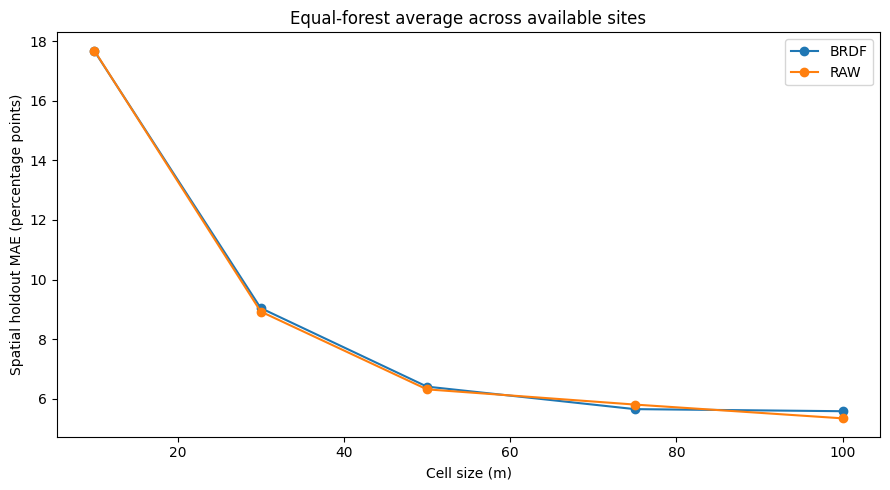

mean    std
scale_m site                  
10      Baego     0.275  0.955
        MOS      -0.057  0.142
        Yangambi -0.072  0.235
        Yoko     -0.206  0.015
30      Baego     0.624  0.350
        MOS      -0.052  0.069
        Yangambi -0.063  0.277
        Yoko     -0.044  0.285
50      Baego     0.396  0.482
        MOS      -0.152  0.035
        Yangambi  0.037  0.068
        Yoko      0.086  0.212
75      Baego    -0.413  0.132
        MOS      -0.037  0.092
        Yangambi  0.062  0.093
        Yoko     -0.225  0.298
100     Baego     0.965  1.308
        MOS       0.075  0.123
        Yangambi  0.000  0.170
        Yoko     -0.083  1.040

Output directory: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final


In [46]:
# 07 — Summarize experiments; paired same-cell BRDF-minus-RAW
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
rows=[];paired=[];pred_tables=[]
for scale in SCALES:
    for rep in range(REPEATS):
        data={}
        for variant in ("RAW","BRDF"):
            f=OUTPUT/"04_validation"/f"{scale}m"/variant/f"heldout_rep{rep}.parquet"
            if f.exists():
                p=pd.read_parquet(f)
                p["scale_m"]=scale;p["variant"]=variant;p["repeat"]=rep
                data[variant]=p;pred_tables.append(p)
                for site,sub in p.groupby("site"):
                    y=sub.observed.to_numpy(float);pred=sub.predicted.to_numpy(float)
                    rows.append(dict(scale_m=scale,variant=variant,repeat=rep,site=site,
                        n=len(y),R2=r2_score(y,pred) if np.var(y)>1e-12 else np.nan,
                        MAE_pp=100*np.mean(np.abs(pred-y)),bias_pp=100*np.mean(pred-y),
                        high_bias_pp=100*np.mean((pred-y)[y>=.4]) if (y>=.4).any() else np.nan))
        if set(data)=={"RAW","BRDF"}:
            keys=["site","row","col"]
            m=data["RAW"].merge(data["BRDF"],on=keys,validate="one_to_one",suffixes=("_raw","_brdf"))
            assert len(m)==len(data["RAW"])==len(data["BRDF"]),("Test sets differ",scale,rep)
            assert np.allclose(m.observed_raw,m.observed_brdf,atol=1e-7)
            for site,p in m.groupby("site"):
                raw=100*np.mean(np.abs(p.predicted_raw-p.observed_raw))
                brdf=100*np.mean(np.abs(p.predicted_brdf-p.observed_brdf))
                paired.append(dict(scale_m=scale,repeat=rep,site=site,
                    raw_MAE_pp=raw,brdf_MAE_pp=brdf,
                    change_MAE_pp=brdf-raw))
if not rows:
    print("No validation runs yet: set RUN_MODELS=True after preparing the satellite samples.")
else:
    metrics=pd.DataFrame(rows)
    metrics.to_csv(OUTPUT/"04_validation"/"heldout_metrics_all.csv",index=False)
    report=metrics.groupby(["scale_m","variant","site"]).agg(
        MAE_pp=("MAE_pp","mean"),MAE_sd=("MAE_pp","std"),
        R2=("R2","mean"),bias_pp=("bias_pp","mean"),
        high_bias_pp=("high_bias_pp","mean")).reset_index()
    display(report.round(3))
    report.to_csv(OUTPUT/"04_validation"/"report_site_metrics.csv",index=False)
    fig,ax=plt.subplots(figsize=(9,5))
    for variant,g in report.groupby("variant"):
        means=g.groupby("scale_m").MAE_pp.mean()
        ax.plot(means.index,means.values,marker="o",label=variant)
    ax.set(xlabel="Cell size (m)",ylabel="Spatial holdout MAE (percentage points)",
           title="Equal-forest average across available sites")
    ax.legend();fig.tight_layout()
    fig.savefig(OUTPUT/"05_figures"/"MAE_vs_resolution_raw_BRDF.png",dpi=200)
    plt.show()
    pred=pd.concat(pred_tables,ignore_index=True)
    pred.to_parquet(OUTPUT/"04_validation"/"all_heldout_predictions.parquet",index=False)
    # Held-out scatter diagnostics, faceted by site for each available scale.
    for (scale,variant),g in pred.groupby(["scale_m","variant"]):
        fig,axs=plt.subplots(2,2,figsize=(10,9),constrained_layout=True)
        for ax,site in zip(axs.flat,YEARS):
            sub=g[g.site==site]
            x=100*sub.observed.to_numpy(float);y=100*sub.predicted.to_numpy(float)
            ax.scatter(x,y,s=6,alpha=.23,rasterized=True)
            ax.plot([0,100],[0,100],ls="--",color="gray",lw=.8)
            ax.set(xlim=(0,100),ylim=(0,100),title=f"{site} (n={len(sub)})",
                   xlabel="UAV Musanga cover (%)",ylabel="Satellite prediction (%)")
        fig.suptitle(f"Spatially held-out Musanga — {scale} m — {variant}")
        fig.savefig(OUTPUT/"05_figures"/f"heldout_scatter_{scale}m_{variant}.png",dpi=170)
        plt.close(fig)
if paired:
    pair=pd.DataFrame(paired)
    pair.to_csv(OUTPUT/"04_validation"/"paired_BRDF_effect.csv",index=False)
    display(pair.groupby(["scale_m","site"]).change_MAE_pp.agg(["mean","std"]).round(3))
else:print("Paired BRDF result unavailable until both corrected and raw inputs have passed all stages.")
print("Output directory:",OUTPUT)

ARCHIVED BENCHMARK NB04 weighted-v4


,model,site,n_test_mean,R2,MAE_pp,RMSE_pp,bias_pp,n_high_mean,high_bias_pp
0,Current 100m RAW,Baego,12.333,0.523,3.896,5.179,-0.078,0.667,-3.951
1,Current 100m RAW,MOS,349.333,0.363,7.964,10.658,3.768,25.667,-10.221
2,Current 100m RAW,Yangambi,29.333,0.214,1.677,2.156,-0.387,0.000,NaN
3,Current 100m RAW,Yoko,37.667,0.249,7.821,10.157,-4.044,3.000,-21.454
4,NB04 weighted-v4,Baego,14.000,-1.521,3.931,5.621,-0.387,1.000,-11.642
5,NB04 weighted-v4,MOS,267.000,0.368,7.872,10.703,3.340,21.333,-10.298
6,NB04 weighted-v4,Yangambi,45.667,-0.258,1.669,2.222,0.216,0.000,NaN
7,NB04 weighted-v4,Yoko,29.667,0.337,5.846,7.733,-2.177,0.667,-17.800


balanced_R2        balanced_MAE_pp        balanced_bias_pp  \
                        mean    std            mean    std             mean   
model                                                                         
Current 100m RAW       0.568  0.028           5.339  0.787           -0.186   
NB04 weighted-v4       0.583  0.150           4.830  0.173            0.248   

                         
                    std  
model                    
Current 100m RAW  1.323  
NB04 weighted-v4  0.499

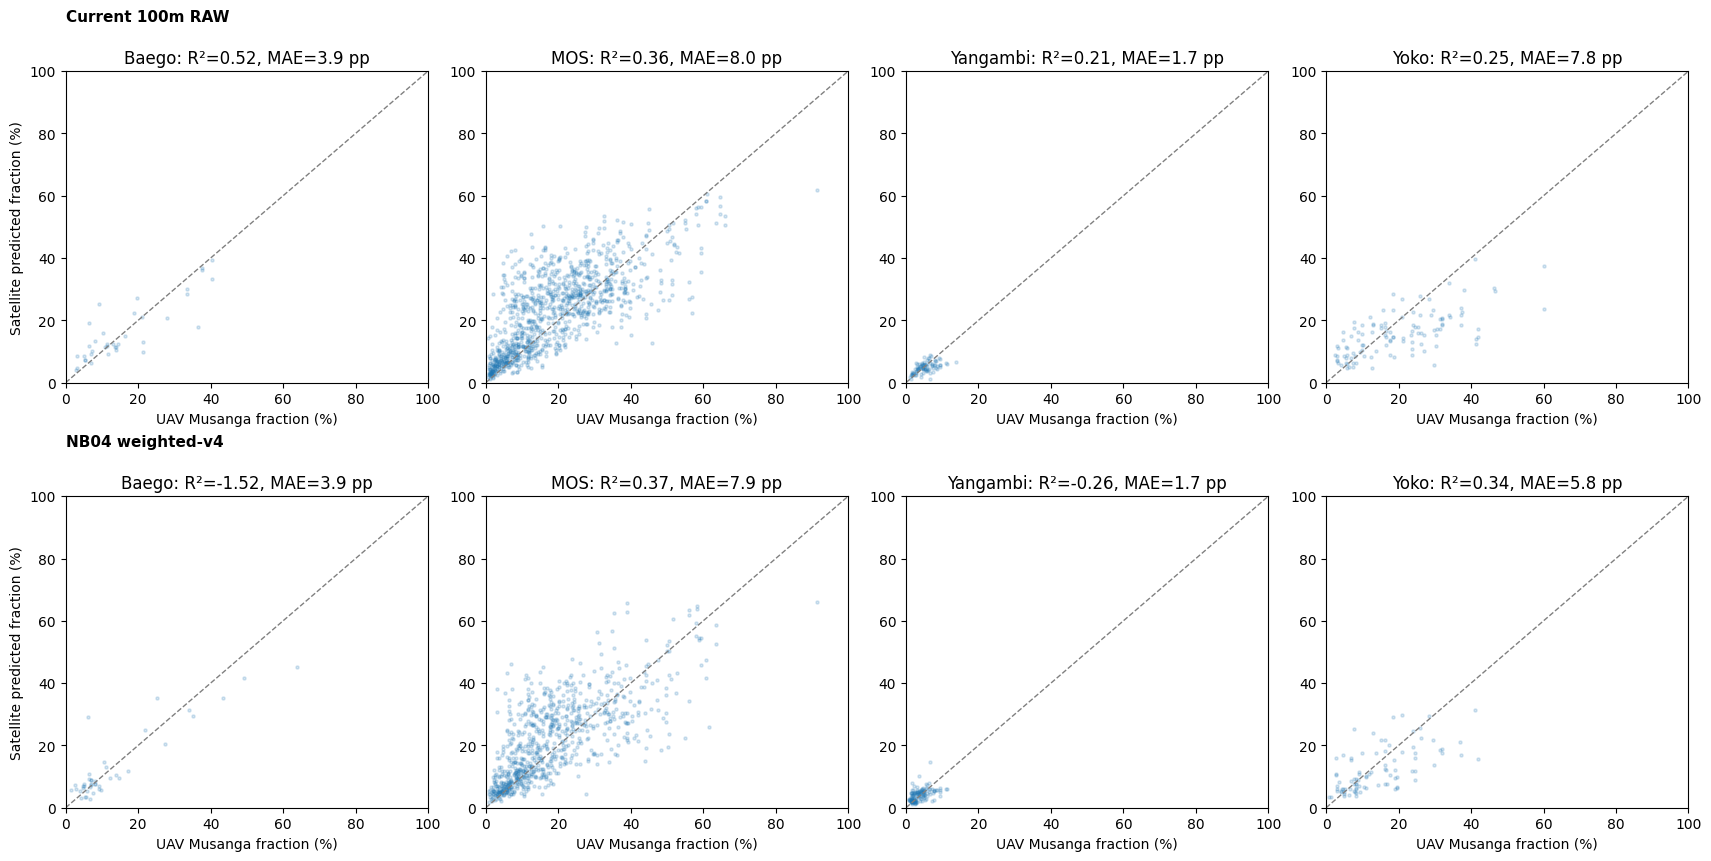

,repeat,n_new,n_archived,n_common,common_fraction_new,median_target_difference,p95_target_difference
0,0,446,371,0,0.0,NaN,NaN
1,1,421,356,0,0.0,NaN,NaN
2,2,419,342,0,0.0,NaN,NaN


CAUTION: These are separate spatial validation runs. Scores are NOT a paired model comparison unless test support is identical.
BENCHMARK OUTPUT /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/05_figures/100m_benchmark


In [47]:
# 08 — 100m benchmark: archived successful NB04 versus current held-out results
# Reads existing predictions ONLY; no model fitting, export, or cache overwrite.
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from IPython.display import display
OLD_VALID=ROOT/"Outputs/V3_1/04_uncertainty_mapping/validation"
NEW_VALID=OUTPUT/"04_validation"/"100m"/"RAW"
BENCH=OUTPUT/"05_figures"/"100m_benchmark"
BENCH.mkdir(parents=True,exist_ok=True)
FORESTS_08=list(YEARS)
old_candidates=[
    ("NB04 weighted-v4", "heldout_weightedcal_v4_100m_rep{rep}.parquet"),
    ("NB04 stratified-v3", "heldout_stratified_v3_100m_rep{rep}.parquet"),
]
source=None
for label,pattern in old_candidates:
    if all((OLD_VALID/pattern.format(rep=rep)).exists() for rep in range(REPEATS)):
        source=(label,pattern);break
if source is None:
    print("ARCHIVED NB04 predictions not found under",OLD_VALID)
    print("Current 100m scatterplots will still be generated. No old baseline invented.")
else:
    print("ARCHIVED BENCHMARK",source[0])
records=[]
for rep in range(REPEATS):
    p=NEW_VALID/f"heldout_rep{rep}.parquet"
    assert p.exists(),f"Current 100m held-out data missing: {p}"
    current=pd.read_parquet(p)
    current["model"]="Current 100m RAW";current["repeat"]=rep
    records.append(current)
    if source:
        old=pd.read_parquet(OLD_VALID/source[1].format(rep=rep))
        assert {"site","group","row","col","observed","predicted"}.issubset(old.columns)
        old["model"]=source[0];old["repeat"]=rep
        records.append(old)
pred08=pd.concat(records,ignore_index=True)
models08=pred08.model.unique().tolist()
# One row per forest and model, with equal repeat weighting (not MOS-weighted).
stats=[]
for (model,site,rep),p in pred08.groupby(["model","site","repeat"]):
    y=p.observed.to_numpy(float);yp=p.predicted.to_numpy(float)
    high=y>=.4
    stats.append(dict(model=model,site=site,repeat=rep,n=len(p),
        MAE_pp=100*np.mean(np.abs(yp-y)),RMSE_pp=100*np.sqrt(np.mean((yp-y)**2)),
        R2=r2_score(y,yp) if np.var(y)>1e-12 else np.nan,
        bias_pp=100*np.mean(yp-y),n_high=int(high.sum()),
        high_bias_pp=100*np.mean((yp-y)[high]) if high.any() else np.nan))
stat08=pd.DataFrame(stats)
summary08=stat08.groupby(["model","site"],as_index=False).agg(
    n_test_mean=("n","mean"),R2=("R2","mean"),MAE_pp=("MAE_pp","mean"),
    RMSE_pp=("RMSE_pp","mean"),bias_pp=("bias_pp","mean"),
    n_high_mean=("n_high","mean"),high_bias_pp=("high_bias_pp","mean"))
display(summary08.round(3))
summary08.to_csv(BENCH/"site_scores_archived_vs_current.csv",index=False)
# Original global R2: forest weights are equal, before combining site test populations.
global08=[]
for (model,rep),g in pred08.groupby(["model","repeat"]):
    y=g.observed.to_numpy(float);yp=g.predicted.to_numpy(float)
    sites=g.site.to_numpy()
    w=np.array([1/(len(FORESTS_08)*np.sum(sites==site)) for site in sites])
    mu=np.dot(w,y);den=np.dot(w,(y-mu)**2)
    global08.append(dict(model=model,repeat=rep,n=len(g),
      balanced_R2=(1-np.dot(w,(y-yp)**2)/den if den>0 else np.nan),
      balanced_MAE_pp=100*np.dot(w,np.abs(y-yp)),
      balanced_bias_pp=100*np.dot(w,yp-y)))
global08=pd.DataFrame(global08)
display(global08.groupby("model")[["balanced_R2","balanced_MAE_pp","balanced_bias_pp"]].agg(["mean","std"]).round(3))
global08.to_csv(BENCH/"equal_forest_scores_per_repeat.csv",index=False)
# Scatterplots: four forests, archived and current (each point a held-out prediction).
fig,axs=plt.subplots(len(models08),4,figsize=(17,4.25*len(models08)),
                     squeeze=False,constrained_layout=True)
for mi,model in enumerate(models08):
    for j,site in enumerate(FORESTS_08):
        ax=axs[mi,j]
        p=pred08[(pred08.model==model)&(pred08.site==site)]
        x=100*p.observed.to_numpy(float);y=100*p.predicted.to_numpy(float)
        ax.scatter(x,y,s=5,alpha=.18,rasterized=True)
        ax.plot([0,100],[0,100],ls="--",color="gray",lw=1)
        z=summary08[(summary08.model==model)&(summary08.site==site)].iloc[0]
        ax.set(title=f"{site}: R²={z.R2:.2f}, MAE={z.MAE_pp:.1f} pp",
               xlim=(0,100),ylim=(0,100),
               xlabel="UAV Musanga fraction (%)",
               ylabel="Satellite predicted fraction (%)" if j==0 else "")
    axs[mi,0].annotate(model,xy=(0,1.16),xycoords="axes fraction",
                       fontsize=11,fontweight="bold")
fig.savefig(BENCH/"scatter_100m_NB04_vs_current.png",dpi=180)
plt.show()
# Check whether archived and new splits share held-out cells; DO NOT claim paired
# scores unless both keys and UAV fractions truly match.
if source:
    overlap=[]
    for rep in range(REPEATS):
        a=pred08[(pred08.model==models08[0])&(pred08.repeat==rep)]
        b=pred08[(pred08.model==source[0])&(pred08.repeat==rep)]
        keys=["site","group","row","col"]
        common=a.merge(b,on=keys,suffixes=("_new","_old"),validate="one_to_one")
        delta=np.abs(common.observed_new-common.observed_old) if len(common) else np.array([])
        overlap.append(dict(repeat=rep,n_new=len(a),n_archived=len(b),
            n_common=len(common),
            common_fraction_new=len(common)/len(a),
            median_target_difference=(float(np.median(delta)) if len(delta) else np.nan),
            p95_target_difference=(float(np.quantile(delta,.95)) if len(delta) else np.nan)))
    overlap=pd.DataFrame(overlap)
    display(overlap.round(4))
    overlap.to_csv(BENCH/"spatial_overlap_archived_vs_current.csv",index=False)
    print("CAUTION: These are separate spatial validation runs. Scores are NOT a paired model comparison unless test support is identical.")
print("BENCHMARK OUTPUT",BENCH)


GLOBAL VALIDATION — EQUAL FOREST (mean across 3 spatial hold-out repeats)


,scale_m,variant,R2,R2_repeat_sd,MAE_pp,RMSE_pp,bias_pp,RPD,RPIQ,high_bias_pp,n_high
0,30,BRDF,0.292,0.164,9.041,12.583,5.014,1.206,1.148,-13.615,506.667
2,30,RAW,0.302,0.151,8.925,12.513,4.801,1.212,1.153,-13.936,506.667
4,50,BRDF,0.502,0.046,6.404,9.315,1.786,1.420,1.646,-12.712,154.333
6,50,RAW,0.505,0.060,6.312,9.286,1.767,1.426,1.656,-12.221,154.333
8,75,BRDF,0.480,0.203,5.649,8.180,1.728,1.435,1.513,-9.514,88.000
10,75,RAW,0.456,0.203,5.802,8.381,1.926,1.400,1.475,-9.286,88.000
12,100,BRDF,0.547,0.074,5.578,8.150,-0.403,1.495,1.951,-12.684,29.333
14,100,NB04 weighted-v4,0.583,0.150,4.830,7.351,0.248,1.614,1.819,-12.270,23.000
16,100,RAW,0.568,0.028,5.339,8.007,-0.186,1.523,1.970,-12.890,29.333


GLOBAL VALIDATION — POOLED (MOS-dominated, shown for comparison)


,scale_m,variant,R2,MAE_pp,RMSE_pp,bias_pp,RPD,RPIQ,high_bias_pp
1,30,BRDF,0.254,11.839,15.225,6.852,1.167,1.419,-13.362
3,30,RAW,0.250,11.871,15.266,6.776,1.164,1.416,-13.717
5,50,BRDF,0.333,9.058,12.267,4.898,1.226,1.546,-9.572
7,50,RAW,0.321,9.166,12.380,5.063,1.215,1.531,-9.416
9,75,BRDF,0.418,7.953,11.065,3.740,1.323,1.712,-8.648
11,75,RAW,0.421,8.006,11.049,3.823,1.324,1.713,-9.018
13,100,BRDF,0.400,7.506,10.382,2.760,1.318,1.940,-10.338
15,100,NB04 weighted-v4,0.476,6.749,9.645,2.336,1.386,1.729,-10.660
17,100,RAW,0.421,7.437,10.206,2.672,1.340,1.972,-11.314


NB04 is a separate benchmark, not paired to the new spatial validation folds.


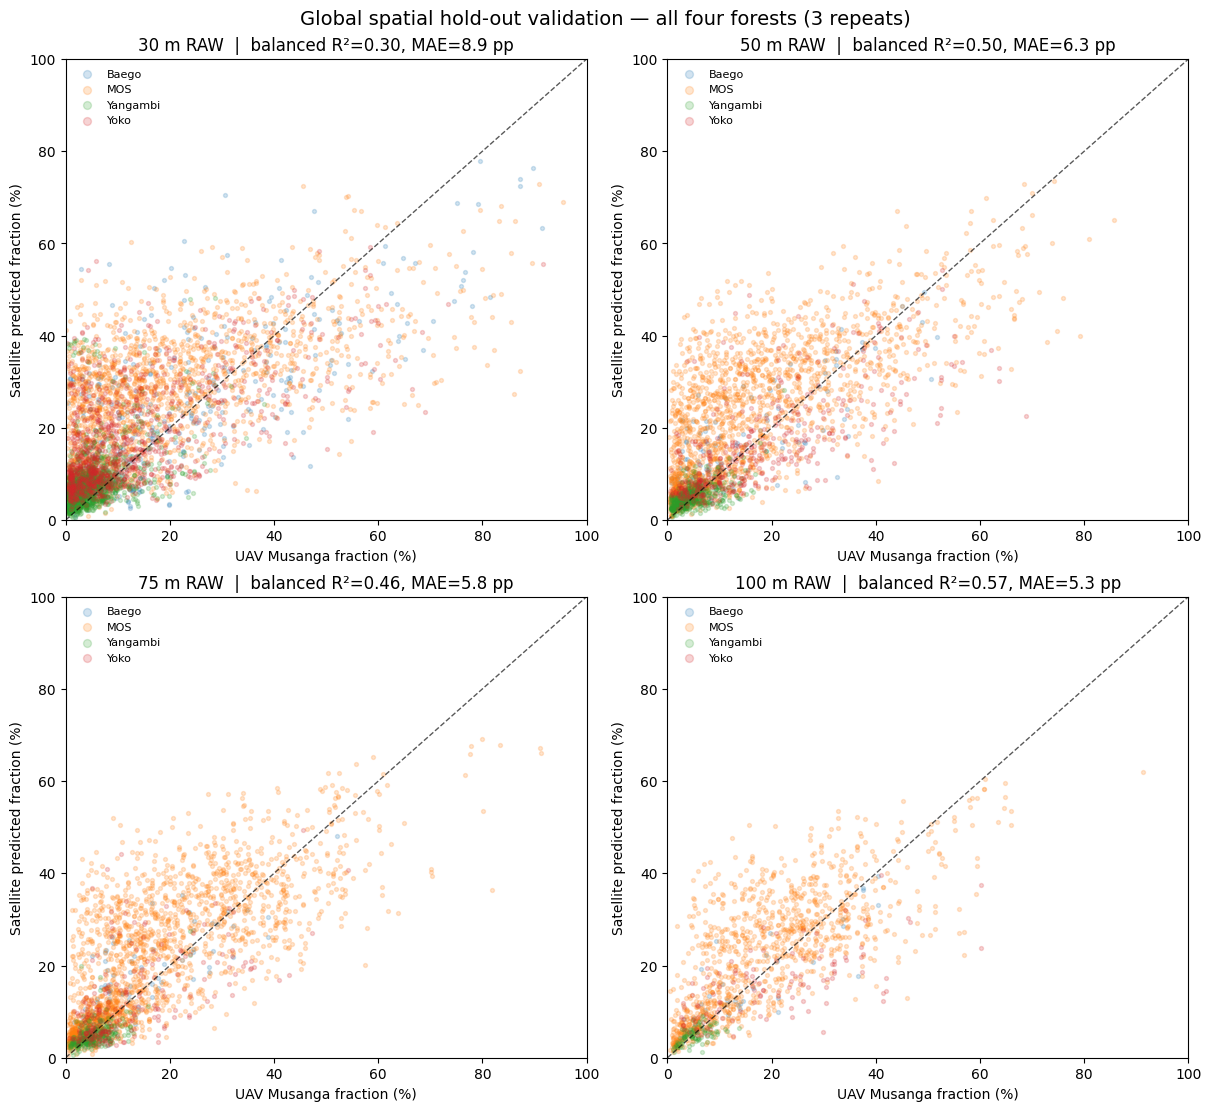

MOS ABUNDANCE BIAS — RAW, spatially held-out (positive=overprediction)


n  bias_pp  MAE_pp
scale_m observed_bin                          
30      0-10%         1365.67    14.78   14.90
        10-20%         711.67    12.47   13.56
        20-40%         761.00     3.39    8.70
        >=40%          463.33   -13.74   15.44
50      0-10%          605.00     9.76   10.08
        10-20%         344.67     9.07   11.09
        20-40%         328.67     3.30    8.74
        >=40%          140.33    -8.78   11.10
75      0-10%          290.67     7.14    7.55
        10-20%         202.33     7.80   10.17
        20-40%         201.00     3.65    8.61
        >=40%           86.00    -8.88   11.03
100     0-10%          104.33     6.96    7.30
        10-20%          91.67     7.20    9.28
        20-40%         127.67     1.56    6.96
        >=40%           25.67   -10.22   11.43

Saved to /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/05_figures/global_validation and /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/04_validation


In [48]:
# 09 — Global held-out validation: pooled + equal-forest metrics, RPD/RPIQ, scatterplots
# READ ONLY. Reuses saved Block 06 predictions and original NB04 archived benchmark.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score
from IPython.display import display

VAL09=OUTPUT/"04_validation"
FIG09=OUTPUT/"05_figures"/"global_validation"
FIG09.mkdir(parents=True,exist_ok=True)
SCALES09=(30,50,75,100)  # 10m available too; main landscape comparison is 30–100m
SITES09=list(YEARS)
VARIANTS09=("RAW","BRDF")
HIGH09=.40

def weighted_quantile09(values,weights,q):
    values=np.asarray(values,float);weights=np.asarray(weights,float)
    order=np.argsort(values)
    v=values[order];w=weights[order]
    c=(np.cumsum(w)-.5*w)/w.sum()
    return float(np.interp(q,c,v,left=v[0],right=v[-1]))

def score09(frame,balanced=False):
    y=frame.observed.to_numpy(float);p=frame.predicted.to_numpy(float)
    sites=frame.site.to_numpy()
    if balanced:
        # Every represented forest contributes exactly 1 / n_forests.
        present=np.unique(sites)
        w=np.array([1/(len(present)*np.sum(sites==s)) for s in sites])
    else:
        w=np.full(len(y),1/len(y))
    mu=np.sum(w*y)
    target_sd=np.sqrt(np.sum(w*(y-mu)**2))
    mse=np.sum(w*(p-y)**2)
    rmse=np.sqrt(mse)
    iqr=weighted_quantile09(y,w,.75)-weighted_quantile09(y,w,.25)
    high=y>=HIGH09
    if high.any():
        wh=w[high]/w[high].sum()
        high_bias=100*np.sum(wh*(p[high]-y[high]))
        high_mae=100*np.sum(wh*np.abs(p[high]-y[high]))
    else: high_bias=high_mae=np.nan
    return dict(n=len(y),n_high=int(high.sum()),
        R2=(1-mse/target_sd**2 if target_sd>1e-10 else np.nan),
        MAE_pp=100*np.sum(w*np.abs(p-y)),RMSE_pp=100*rmse,
        bias_pp=100*np.sum(w*(p-y)),
        RPD=(target_sd/rmse if rmse>0 else np.nan),
        RPIQ=(iqr/rmse if rmse>0 else np.nan),
        target_SD_pp=100*target_sd,target_IQR_pp=100*iqr,
        high_bias_pp=high_bias,high_MAE_pp=high_mae)

records09=[];saved09={}
for scale in SCALES09:
    for variant in VARIANTS09:
        for rep in range(REPEATS):
            f=VAL09/f"{scale}m"/variant/f"heldout_rep{rep}.parquet"
            assert f.is_file(),("Missing held-out predictions",f)
            d=pd.read_parquet(f)
            assert {"site","group","row","col","observed","predicted"}.issubset(d.columns)
            assert d.observed.between(0,1).all() and d.predicted.between(0,1).all()
            assert set(d.site)==set(SITES09),("Incomplete forest support",f)
            saved09[scale,variant,rep]=d
            for scheme,balanced in [("pooled",False),("equal_forest",True)]:
                records09.append(dict(scale_m=scale,variant=variant,repeat=rep,
                    weighting=scheme,**score09(d,balanced)))
# Add original validated 100m NB04 only as a SEPARATE benchmark, never as a paired run.
oldroot09=ROOT/"Outputs/V3_1/04_uncertainty_mapping/validation"
oldpatterns09=[
    ("NB04 weighted-v4","heldout_weightedcal_v4_100m_rep{rep}.parquet"),
    ("NB04 stratified-v3","heldout_stratified_v3_100m_rep{rep}.parquet")]
archived09=None
for name,pattern in oldpatterns09:
    if all((oldroot09/pattern.format(rep=i)).is_file() for i in range(REPEATS)):
        archived09=name
        for rep in range(REPEATS):
            d=pd.read_parquet(oldroot09/pattern.format(rep=rep))
            for scheme,balanced in [("pooled",False),("equal_forest",True)]:
                records09.append(dict(scale_m=100,variant=name,repeat=rep,
                    weighting=scheme,**score09(d,balanced)))
        break

per_repeat09=pd.DataFrame(records09)
per_repeat09.to_csv(VAL09/"global_validation_per_repeat.csv",index=False)
metric_names09=["R2","MAE_pp","RMSE_pp","bias_pp","RPD","RPIQ",
                "high_bias_pp","high_MAE_pp","n","n_high","target_SD_pp","target_IQR_pp"]
summary09=per_repeat09.groupby(["scale_m","variant","weighting"],as_index=False)[metric_names09].mean()
sd09=per_repeat09.groupby(["scale_m","variant","weighting"])[
    ["R2","MAE_pp","RMSE_pp","RPD","RPIQ"]].std().reset_index().rename(columns={
    x:x+"_repeat_sd" for x in ["R2","MAE_pp","RMSE_pp","RPD","RPIQ"]})
summary09=summary09.merge(sd09,on=["scale_m","variant","weighting"])
summary09.to_csv(VAL09/"global_validation_summary.csv",index=False)
print("GLOBAL VALIDATION — EQUAL FOREST (mean across 3 spatial hold-out repeats)")
display(summary09[summary09.weighting=="equal_forest"][
    ["scale_m","variant","R2","R2_repeat_sd","MAE_pp","RMSE_pp","bias_pp",
     "RPD","RPIQ","high_bias_pp","n_high"]].round(3))
print("GLOBAL VALIDATION — POOLED (MOS-dominated, shown for comparison)")
display(summary09[summary09.weighting=="pooled"][
    ["scale_m","variant","R2","MAE_pp","RMSE_pp","bias_pp","RPD","RPIQ",
     "high_bias_pp"]].round(3))
print("NB04 is a separate benchmark, not paired to the new spatial validation folds.")

# Four panels, one per resolution; coloured by forest (display-only capped scatter).
palette09=plt.get_cmap("tab10")
fig,axes=plt.subplots(2,2,figsize=(12,11),constrained_layout=True)
for ax,scale in zip(axes.flat,SCALES09):
    frames=[saved09[scale,"RAW",rep] for rep in range(REPEATS)]
    d=pd.concat(frames,ignore_index=True)
    for j,site in enumerate(SITES09):
        z=d[d.site==site]
        # Display cap avoids MOS obscuring all other forests; metrics use ALL points.
        if len(z)>1800: z=z.sample(n=1800,random_state=20261022+j+scale)
        ax.scatter(100*z.observed,100*z.predicted,alpha=.20,s=8,
                   color=palette09(j),label=site,rasterized=True)
    ax.plot([0,100],[0,100],ls="--",lw=1,color="black",alpha=.65)
    g=summary09[(summary09.scale_m==scale)&(summary09.variant=="RAW")&
                (summary09.weighting=="equal_forest")].iloc[0]
    ax.set(xlim=(0,100),ylim=(0,100),xlabel="UAV Musanga fraction (%)",
           ylabel="Satellite predicted fraction (%)",
           title=f"{scale} m RAW  |  balanced R²={g.R2:.2f}, MAE={g.MAE_pp:.1f} pp")
    ax.legend(markerscale=2,frameon=False,loc="upper left",fontsize=8)
fig.suptitle("Global spatial hold-out validation — all four forests (3 repeats)",fontsize=14)
fig.savefig(FIG09/"global_scatter_RAW_30_50_75_100m.png",dpi=200)
plt.show()

# High abundance diagnostics from all held-out RAW pixels, with MOS explicit.
diag09=[]
for scale in SCALES09:
    for variant in VARIANTS09:
        for rep in range(REPEATS):
            d=saved09[scale,variant,rep]
            for site in ["ALL","MOS"]:
                z=d if site=="ALL" else d[d.site=="MOS"]
                for label,lo,hi in [("0-10%",0,.1),("10-20%",.1,.2),
                                    ("20-40%",.2,.4),(">=40%",.4,1.0000001)]:
                    p=z[(z.observed>=lo)&(z.observed<hi)]
                    if len(p):
                        diag09.append(dict(scale_m=scale,variant=variant,repeat=rep,
                            site=site,observed_bin=label,n=len(p),
                            bias_pp=100*(p.predicted-p.observed).mean(),
                            MAE_pp=100*np.abs(p.predicted-p.observed).mean()))
diag09=pd.DataFrame(diag09)
diag09.to_csv(VAL09/"global_abundance_bin_diagnostics.csv",index=False)
print("MOS ABUNDANCE BIAS — RAW, spatially held-out (positive=overprediction)")
display(diag09[(diag09.site=="MOS")&(diag09.variant=="RAW")].groupby(
    ["scale_m","observed_bin"])[["n","bias_pp","MAE_pp"]].mean().round(2))
print("Saved to",FIG09,"and",VAL09)


,scale_m,site,n_display,n_available
0,30,Baego,426,426
1,30,MOS,426,9905
2,30,Yangambi,426,1275
3,30,Yoko,426,1019
4,50,Baego,131,131
5,50,MOS,131,4256
6,50,Yangambi,131,419
7,50,Yoko,131,412
8,75,Baego,80,80
9,75,MOS,80,2340


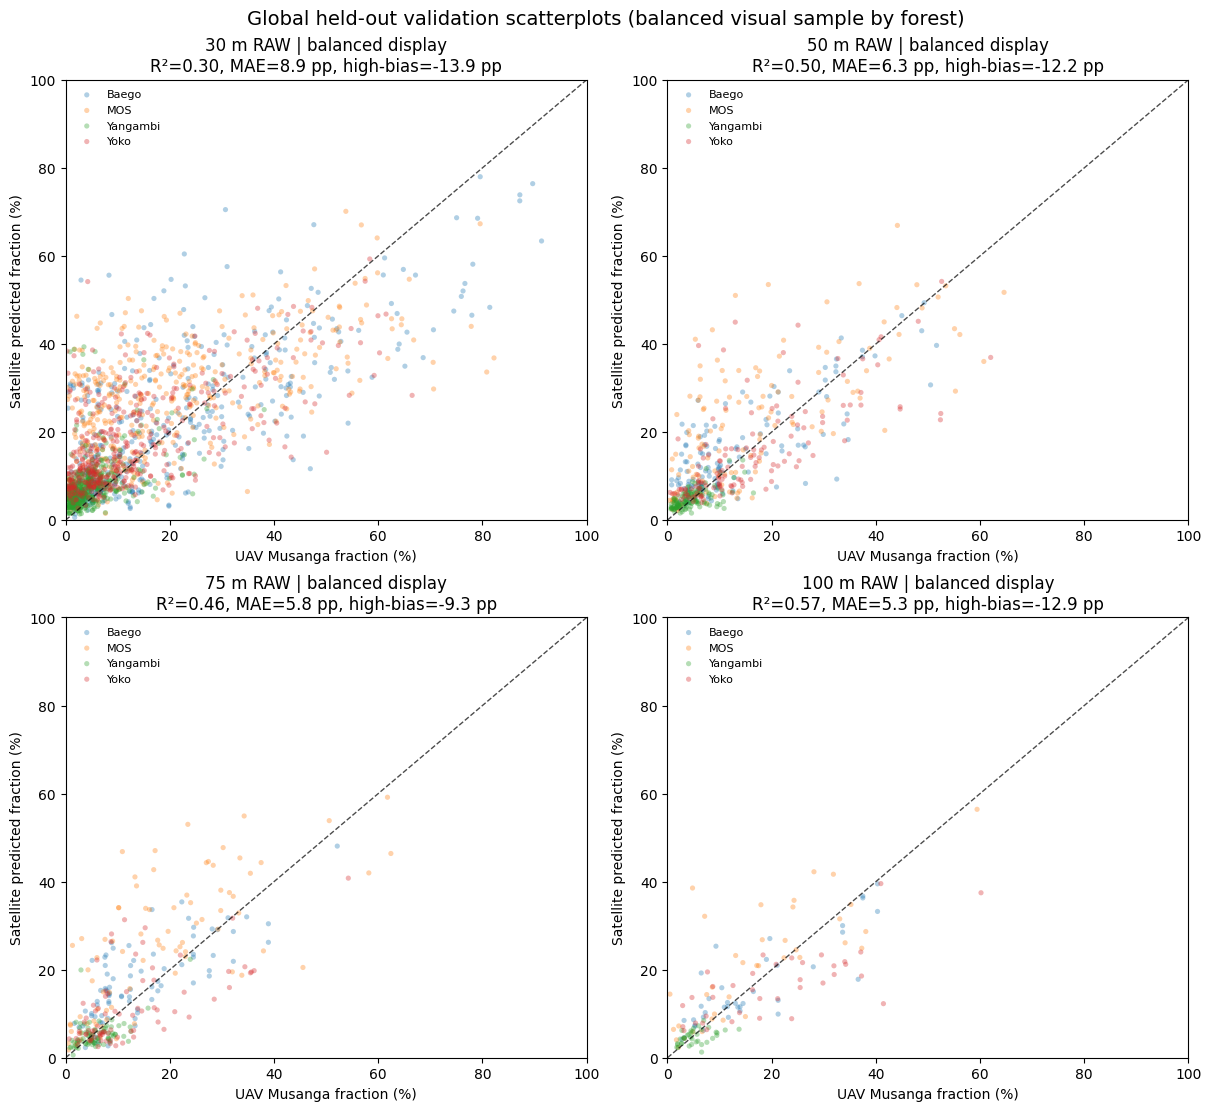

Saved: /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/05_figures/global_validation/global_scatter_RAW_balanced_display_30_50_75_100m.png


In [49]:
# 09B — Clearer global scatterplots with balanced display by forest
# Display-only balancing: metrics remain based on ALL held-out cells.

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

SCALES = [30, 50, 75, 100]
VARIANT = "RAW"   # change to "BRDF" if wanted
SEED = 20261022
MAX_PER_FOREST = 600   # cap for plotting only

VAL_DIR = OUTPUT / "04_validation"
FIG_DIR = OUTPUT / "05_figures" / "global_validation"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# load summary table from Block 09
summary = pd.read_csv(VAL_DIR / "global_validation_summary.csv")

# load held-out predictions
all_frames = {}
for scale in SCALES:
    parts = []
    for rep in range(REPEATS):
        f = VAL_DIR / f"{scale}m" / VARIANT / f"heldout_rep{rep}.parquet"
        d = pd.read_parquet(f).copy()
        d["repeat"] = rep
        parts.append(d)
    all_frames[scale] = pd.concat(parts, ignore_index=True)

# make balanced plotting sample
balanced_samples = {}
sample_counts = []
for scale, d in all_frames.items():
    counts = d["site"].value_counts().sort_index()
    n_per_site = min(counts.min(), MAX_PER_FOREST)
    balanced = []
    for i, site in enumerate(sorted(d["site"].unique())):
        z = d[d.site == site]
        if len(z) > n_per_site:
            z = z.sample(n=n_per_site, random_state=SEED + scale + i)
        balanced.append(z)
        sample_counts.append({"scale_m": scale, "site": site, "n_display": len(z), "n_available": len(d[d.site==site])})
    balanced_samples[scale] = pd.concat(balanced, ignore_index=True)

sample_counts = pd.DataFrame(sample_counts)
display(sample_counts)

# plot
site_order = ["Baego", "MOS", "Yangambi", "Yoko"]
colors = dict(zip(site_order, plt.get_cmap("tab10").colors[:4]))

fig, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)

for ax, scale in zip(axes.flat, SCALES):
    d = balanced_samples[scale]

    for site in site_order:
        z = d[d.site == site]
        if len(z) == 0:
            continue
        ax.scatter(
            100 * z["observed"],
            100 * z["predicted"],
            s=14,
            alpha=0.35,
            label=site,
            color=colors[site],
            edgecolors="none",
            rasterized=True
        )

    ax.plot([0, 100], [0, 100], "--", lw=1, color="black", alpha=0.7)

    row = summary[
        (summary["scale_m"] == scale) &
        (summary["variant"] == VARIANT) &
        (summary["weighting"] == "equal_forest")
    ].iloc[0]

    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("UAV Musanga fraction (%)")
    ax.set_ylabel("Satellite predicted fraction (%)")
    ax.set_title(
        f"{scale} m {VARIANT} | balanced display\n"
        f"R²={row['R2']:.2f}, MAE={row['MAE_pp']:.1f} pp, high-bias={row['high_bias_pp']:.1f} pp"
    )
    ax.legend(frameon=False, fontsize=8, loc="upper left")

fig.suptitle("Global held-out validation scatterplots (balanced visual sample by forest)", fontsize=14)

out_png = FIG_DIR / f"global_scatter_{VARIANT}_balanced_display_30_50_75_100m.png"
fig.savefig(out_png, dpi=220, bbox_inches="tight")
plt.show()

print("Saved:", out_png)

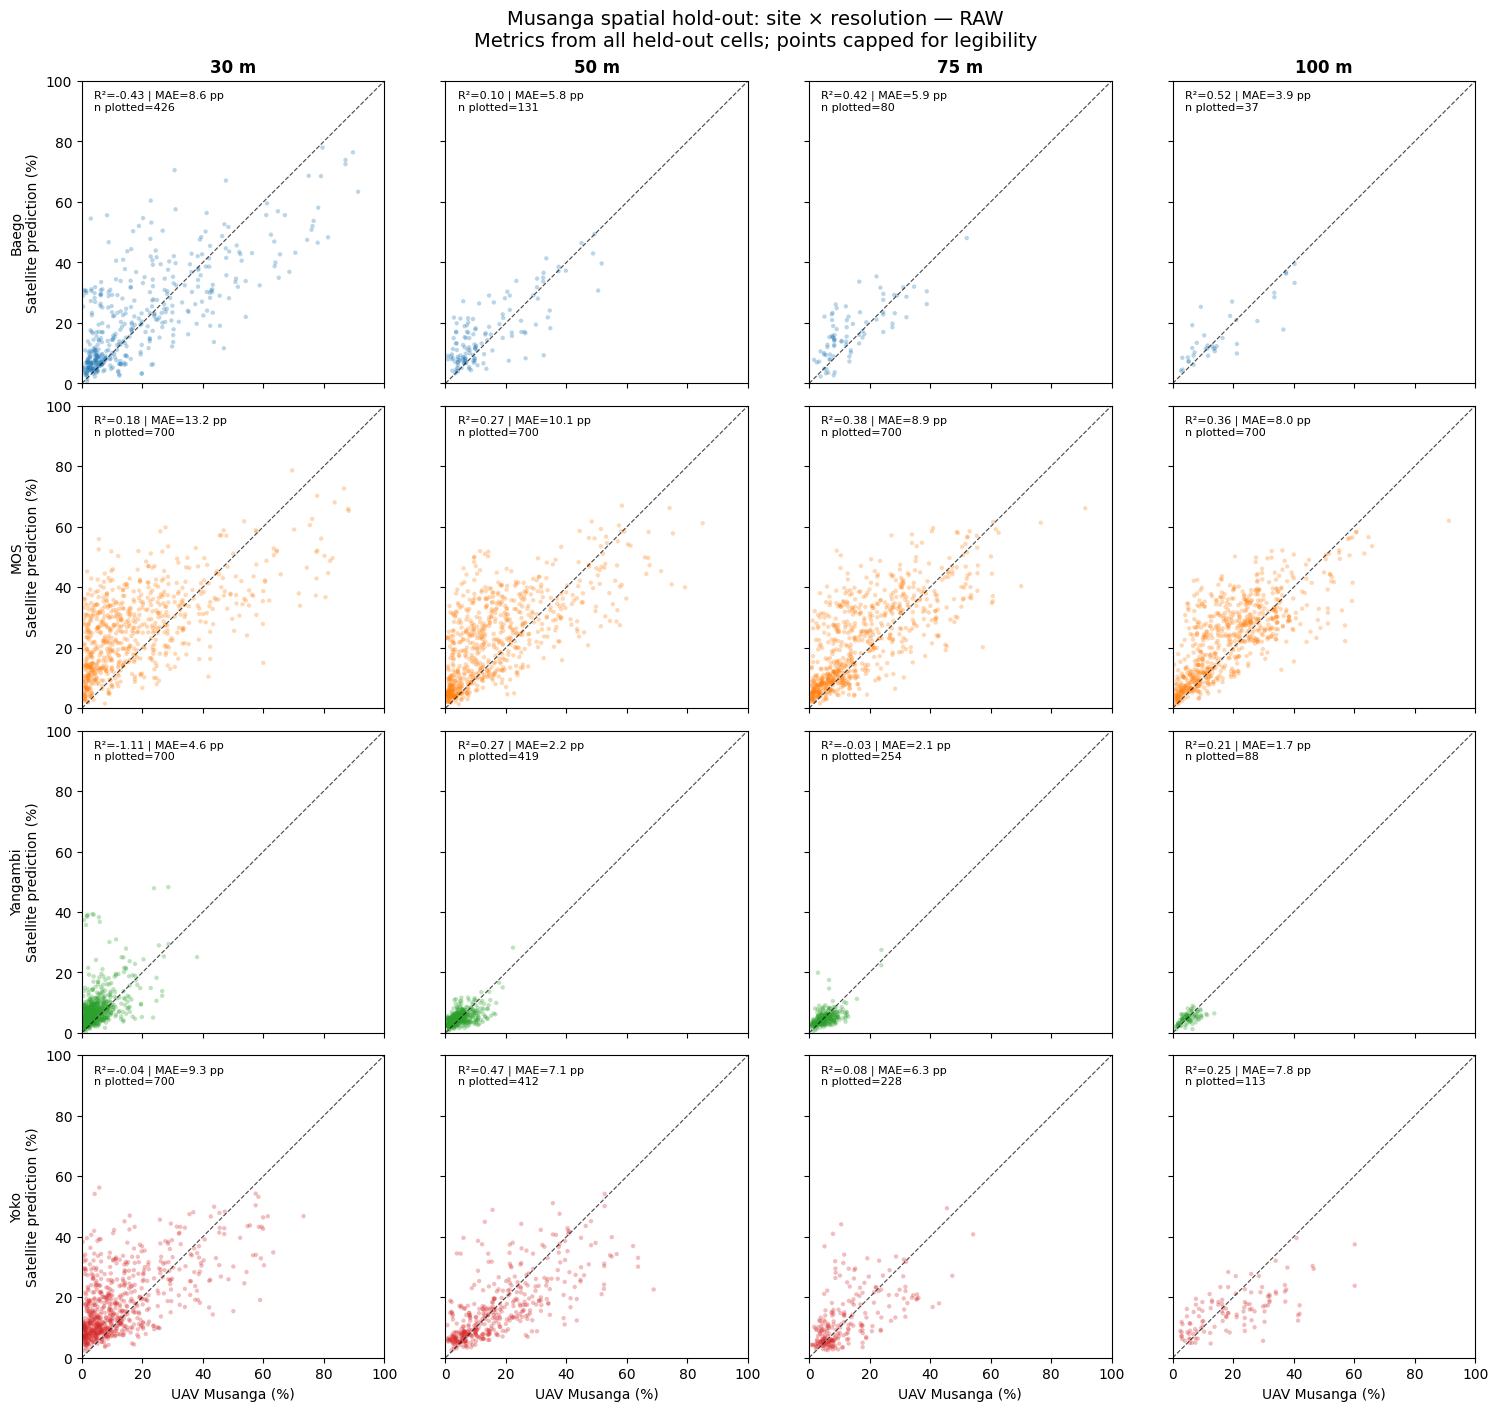

SAVED /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/05_figures/final_validation/scatter_4forests_x_4scales_RAW.png


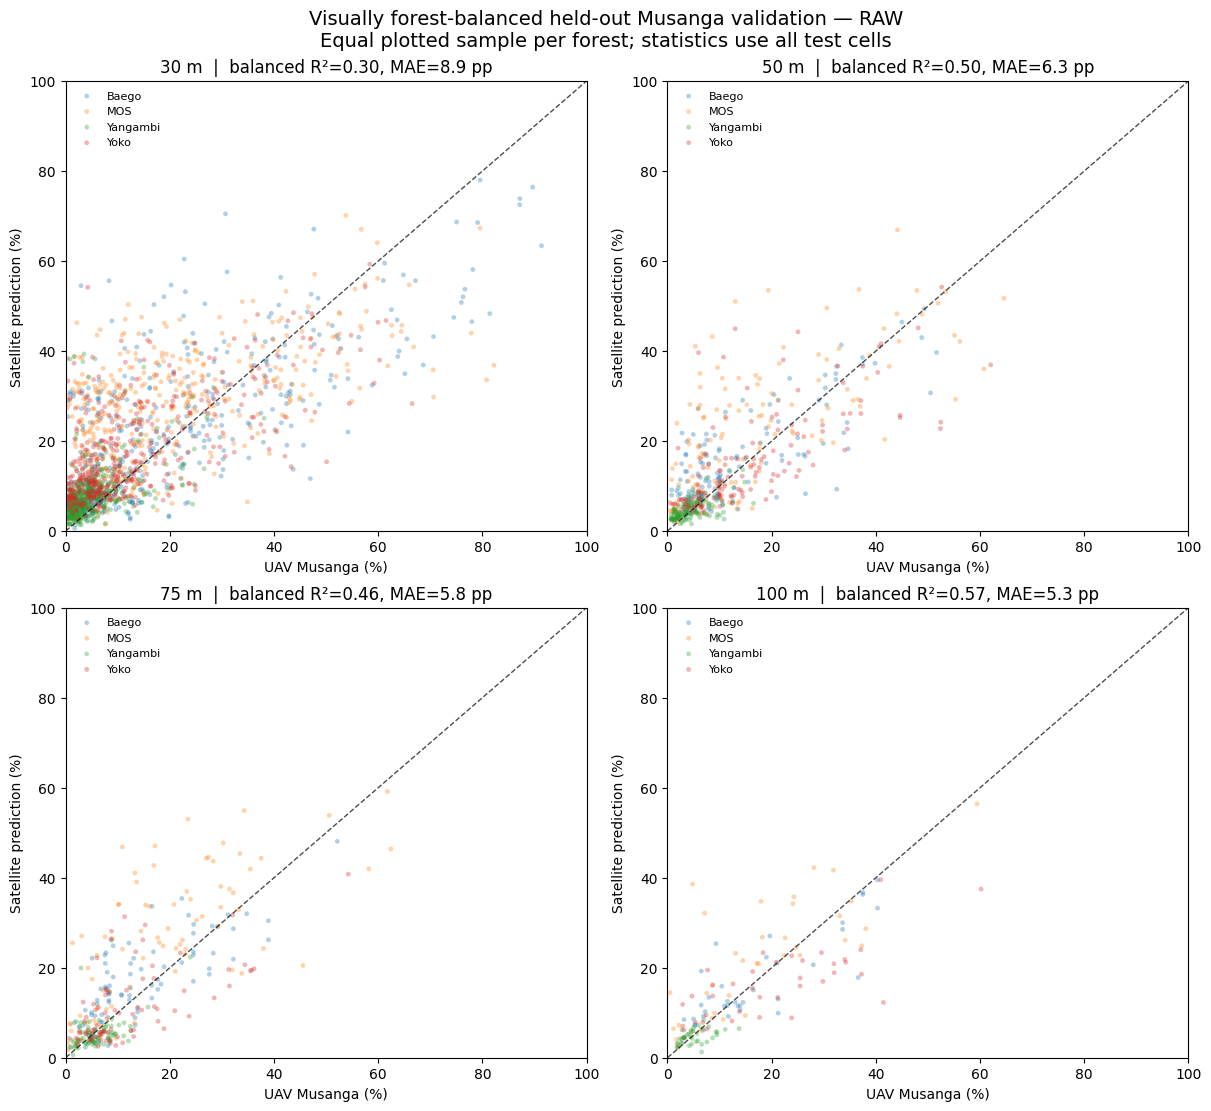

SAVED /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/05_figures/final_validation/scatter_global_forest_balanced_RAW.png
ORIGINAL NB04 100 m benchmark is separate; do not mix its held-out folds.
FIGURE DIRECTORY /content/drive/MyDrive/Colab Notebooks/Musanga/Final/Outputs/V3_1/04_Satellite_Musanga_Final/05_figures/final_validation


In [50]:
# 10 — FINAL FIGURES: per-forest 4x4 and visually balanced global scatterplots
# Saved 30/50/75/100m spatial held-out results only. No model training or reruns.
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import r2_score

SCALES10=(30,50,75,100)
SITES10=("Baego","MOS","Yangambi","Yoko")
VARIANT10="RAW"                       # switch to "BRDF" for comparison
DISPLAY_CAP10=700                    # plotting only; validation uses ALL cells
SEED10=20261022
FIG10=OUTPUT/"05_figures"/"final_validation"
FIG10.mkdir(parents=True,exist_ok=True)
VAL10=OUTPUT/"04_validation"
palette10=dict(zip(SITES10,plt.get_cmap("tab10").colors[:4]))
pred10={}
metrics10=[]
for scale in SCALES10:
    chunks=[]
    for rep in range(REPEATS):
        file=VAL10/f"{scale}m"/VARIANT10/f"heldout_rep{rep}.parquet"
        assert file.is_file(),f"Missing held-out data: {file}"
        d=pd.read_parquet(file).copy()
        assert {"site","observed","predicted","row","col","group"}.issubset(d.columns)
        d["repeat"]=rep
        chunks.append(d)
        for site,z in d.groupby("site"):
            y=z.observed.to_numpy(float);p=z.predicted.to_numpy(float)
            metrics10.append(dict(scale_m=scale,site=site,repeat=rep,
                n=len(z),R2=(r2_score(y,p) if np.var(y)>1e-12 else np.nan),
                MAE_pp=100*np.mean(np.abs(p-y)),bias_pp=100*np.mean(p-y)))
    pred10[scale]=pd.concat(chunks,ignore_index=True)
    assert set(pred10[scale].site)==set(SITES10)
site_metrics10=(pd.DataFrame(metrics10)
    .groupby(["scale_m","site"],as_index=False)
    .agg(R2=("R2","mean"),MAE_pp=("MAE_pp","mean"),
         bias_pp=("bias_pp","mean"),n_test_mean=("n","mean")))
site_metrics10.to_csv(FIG10/f"site_metrics_{VARIANT10}.csv",index=False)

# Figure A — 4 forests (rows) by 4 resolutions (columns)
fig,axs=plt.subplots(4,4,figsize=(15,14),sharex=True,sharey=True,
                     constrained_layout=True)
for i,site in enumerate(SITES10):
    for j,scale in enumerate(SCALES10):
        ax=axs[i,j];z=pred10[scale].query("site == @site")
        n_display=min(len(z),DISPLAY_CAP10)
        z_plot=z.sample(n=n_display,random_state=SEED10+100*i+scale) if len(z)>n_display else z
        ax.scatter(100*z_plot.observed,100*z_plot.predicted,s=10,alpha=.30,
                   c=[palette10[site]],rasterized=True,edgecolors="none")
        ax.plot([0,100],[0,100],"--",lw=.85,color="black",alpha=.7)
        m=site_metrics10[(site_metrics10.site==site)&
                         (site_metrics10.scale_m==scale)].iloc[0]
        ax.text(.04,.97,f"R²={m.R2:.2f} | MAE={m.MAE_pp:.1f} pp\nn plotted={n_display:,}",
                transform=ax.transAxes,ha="left",va="top",fontsize=8,
                bbox=dict(facecolor="white",alpha=.8,edgecolor="none",pad=3))
        ax.set_xlim(0,100);ax.set_ylim(0,100);ax.set_aspect("equal",adjustable="box")
        if i==0:ax.set_title(f"{scale} m",fontsize=12,fontweight="bold")
        if j==0:ax.set_ylabel(f"{site}\nSatellite prediction (%)",fontsize=10)
        if i==len(SITES10)-1:ax.set_xlabel("UAV Musanga (%)",fontsize=10)
fig.suptitle(f"Musanga spatial hold-out: site × resolution — {VARIANT10}\n"
             "Metrics from all held-out cells; points capped for legibility",
             fontsize=14)
pathA=FIG10/f"scatter_4forests_x_4scales_{VARIANT10}.png"
fig.savefig(pathA,dpi=220,bbox_inches="tight")
plt.show()
print("SAVED",pathA)

# Figure B — 2x2 global plots, EQUAL displayed points per forest at each scale.
# Metrics are loaded from Block 09 and NEVER recomputed on visual subsamples.
summary_path=VAL10/"global_validation_summary.csv"
assert summary_path.is_file(),("Run Block 09 once to obtain global metrics",summary_path)
glob10=pd.read_csv(summary_path)
fig,axs=plt.subplots(2,2,figsize=(12,11),constrained_layout=True)
display_records=[]
for ax,scale in zip(axs.flat,SCALES10):
    d=pred10[scale]
    available=d.site.value_counts()
    equal_n=min(int(available.min()),DISPLAY_CAP10)
    for i,site in enumerate(SITES10):
        site_d=d[d.site==site]
        sampled=site_d.sample(n=equal_n,random_state=SEED10+scale+i)
        ax.scatter(100*sampled.observed,100*sampled.predicted,
                   s=12,alpha=.34,color=palette10[site],label=site,
                   rasterized=True,edgecolors="none")
        display_records.append(dict(scale_m=scale,site=site,
                                    n_available=len(site_d),n_display=equal_n))
    ax.plot([0,100],[0,100],"--",lw=1,color="black",alpha=.7)
    m=glob10[(glob10.scale_m==scale)&(glob10.variant==VARIANT10)&
             (glob10.weighting=="equal_forest")].iloc[0]
    ax.set(xlim=(0,100),ylim=(0,100),
           title=f"{scale} m  |  balanced R²={m.R2:.2f}, MAE={m.MAE_pp:.1f} pp",
           xlabel="UAV Musanga (%)",ylabel="Satellite prediction (%)")
    ax.legend(frameon=False,fontsize=8,loc="upper left")
fig.suptitle(f"Visually forest-balanced held-out Musanga validation — {VARIANT10}\n"
             "Equal plotted sample per forest; statistics use all test cells",
             fontsize=14)
pathB=FIG10/f"scatter_global_forest_balanced_{VARIANT10}.png"
fig.savefig(pathB,dpi=220,bbox_inches="tight")
plt.show()
pd.DataFrame(display_records).to_csv(FIG10/f"visual_sampling_{VARIANT10}.csv",index=False)
print("SAVED",pathB)
print("ORIGINAL NB04 100 m benchmark is separate; do not mix its held-out folds.")
print("FIGURE DIRECTORY",FIG10)
